# CO2.2 – Final Project: RF-DETR Pedestrian Detection

## Project Overview
This project implements a transformer-based pedestrian object detection system using RF-DETR. It covers dataset acquisition, preprocessing, model training, evaluation, visualization, and performance analysis.

## Project Objectives
1. Prepare an annotated pedestrian detection dataset.
2. Fine-tune an RF-DETR model using PyTorch.
3. Evaluate accuracy, precision, recall, IoU, and mAP.
4. Visualize model predictions and detection errors.
5. Analyze model performance, limitations, and potential improvements.

## Phase 1 – Environment Setup

In [1]:
# Import PyTorch to check the deep learning environment.
# PyTorch provides GPU acceleration for RF-DETR training.
import torch

# Display the installed PyTorch version.
# This helps identify potential compatibility issues later.
print("PyTorch Version:", torch.__version__)

# Check whether CUDA is available.
# CUDA allows PyTorch to use an NVIDIA GPU.
print("CUDA Available:", torch.cuda.is_available())

# Display the GPU model when CUDA is available.
# Otherwise, inform the user that no GPU was detected.
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. Enable T4 GPU in Runtime settings.")


PyTorch Version: 2.11.0+cu130
CUDA Available: True
GPU Name: Tesla T4


## 1.2 Installation of RF-DETR and Required Libraries

This section installs the necessary Python libraries and dependencies for developing the RF-DETR pedestrian detection system. The official RF-DETR package provides the pretrained object detection architecture and training functionality, while supporting libraries are used for dataset processing, model evaluation, and visualization.

The installation includes RF-DETR with its training dependencies, pycocotools for COCO-based evaluation, OpenCV for image processing, Supervision for object detection visualization, Matplotlib for graphical analysis, and Pandas for organizing experimental results. These libraries establish the software environment required for the succeeding stages of dataset preparation, model training, and performance evaluation.

In [2]:
# Install the official RF-DETR package and its training dependencies.
# These dependencies provide model training, optimization, and checkpointing.
%pip install -q "rfdetr[train]"

# Install COCO evaluation utilities.
# These will help calculate mAP and other object detection metrics.
%pip install -q pycocotools

# Install image processing and visualization utilities.
# These will help us inspect images, bounding boxes, and predictions.
%pip install -q supervision matplotlib pandas opencv-python-headless


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 53.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.7/604.7 kB 48.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.7/102.7 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 60.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 406.3/406.3 kB 23.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.7/409.7 kB 41.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 72.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 678.2/678.2 kB 40.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 81.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 788.9/788.9 kB 43.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 37.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 1.3 Verification of Installed Libraries

This section verifies that the RF-DETR framework and supporting Python libraries have been successfully installed and can be imported into the Google Colab environment. Library verification is performed to identify potential installation issues or missing dependencies before proceeding with dataset preparation and model implementation.

The code imports the RF-DETR model class, COCO evaluation utilities, and Supervision library. It also retrieves the installed RF-DETR version for documentation and reproducibility. Successful execution confirms that the main software dependencies are accessible and that the environment is ready for the next stage of the project.

In [3]:
# Import Python's package metadata utility.
# This allows us to check the installed RF-DETR version.
from importlib.metadata import version

# Import the official RF-DETR model class.
# We will use a smaller model for our initial T4 GPU experiments.
from rfdetr import RFDETRSmall

# Import the COCO evaluation library.
# This will support standardized object detection evaluation.
from pycocotools.coco import COCO

# Import the visualization library.
# Supervision provides convenient bounding box visualization tools.
import supervision as sv

# Display the installed RF-DETR version.
# This will help us document our software environment.
print("RF-DETR Version:", version("rfdetr"))

# Confirm successful imports.
# These messages indicate that the required libraries are accessible.
print("RF-DETR Import: Successful")
print("COCO Evaluation Library: Successful")
print("Supervision Library: Successful")
print("Environment Setup: COMPLETE")


RF-DETR Version: 1.11.2
RF-DETR Import: Successful
COCO Evaluation Library: Successful
Supervision Library: Successful
Environment Setup: COMPLETE


## 2.1 Google Drive Integration and Project Directory Setup

This section integrates Google Drive with the Google Colab environment to establish persistent storage for the RF-DETR pedestrian detection project. Since Google Colab runtime sessions are temporary, Google Drive integration is necessary to preserve datasets, trained model checkpoints, evaluation results, and generated visualizations across different sessions.

The code mounts Google Drive and creates a structured project directory containing dedicated folders for the original dataset, processed dataset, trained models, training outputs, evaluation results, and prediction visualizations. This organization supports efficient data management, experimental reproducibility, and systematic preparation of the final project deliverables.

In [4]:
# Import the Google Drive integration module.
# This allows Colab to access files stored in your Google Drive.
from google.colab import drive

# Mount Google Drive to the Colab environment.
# You will be asked to authorize access to your Google account.
drive.mount('/content/drive')

# Import Path for managing file and folder locations.
# Path provides a convenient way to create and organize directories.
from pathlib import Path

# Define the main directory for the RF-DETR final project.
# All important project files will be stored inside this location.
PROJECT_DIR = Path(
    "/content/drive/MyDrive/CO2.2_RF_DETR_Final_Project"
)

# Define the folders required for dataset preparation and training.
# Separating files by purpose improves project organization.
folder_names = [
    "dataset_original",
    "dataset_processed",
    "models",
    "training_outputs",
    "evaluation_results",
    "visualizations",
    "reports"
]

# Create the main project directory if it does not exist.
# This prevents errors when saving files in later steps.
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

# Create each required subdirectory within the project folder.
# Existing folders will remain unchanged.
for folder_name in folder_names:
    folder_path = PROJECT_DIR / folder_name
    folder_path.mkdir(parents=True, exist_ok=True)
    print(f"Created/Verified: {folder_path}")

# Display a confirmation message after organizing the folders.
# The project is now ready for dataset acquisition and preparation.
print("\nGoogle Drive Integration: COMPLETE")
print("Project Directory:", PROJECT_DIR)


Mounted at /content/drive
Created/Verified: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/dataset_original
Created/Verified: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/dataset_processed
Created/Verified: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/models
Created/Verified: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/training_outputs
Created/Verified: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/evaluation_results
Created/Verified: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/visualizations
Created/Verified: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/reports

Google Drive Integration: COMPLETE
Project Directory: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project


## 3.1 Identification and Verification of Available Datasets

This section identifies existing image datasets stored in Google Drive that may be suitable for training the RF-DETR pedestrian detection model. Dataset identification is an important preliminary step because it allows previously collected and annotated images to be reused while minimizing unnecessary data acquisition and processing.

The code searches for common dataset configuration files, annotation files, and compressed archives associated with object detection datasets. The identified files will be examined to determine their annotation formats, directory structures, and compatibility with RF-DETR. This preliminary verification will guide the selection and preparation of the dataset before model training.

## 3.2 Dataset Location and Initial Inspection

This section identifies and examines the pedestrian detection dataset transferred from the previous computer vision activity. The dataset serves as the primary source of annotated pedestrian images for developing and evaluating the RF-DETR object detection model. Reusing the dataset also supports consistency with the previous object detection experiments.

The code searches the project directory and other locations in Google Drive for available dataset folders and compressed archives. It identifies relevant annotation files, examines the directory structure, and determines whether the dataset is organized in YOLO or COCO format. This preliminary inspection is necessary to establish the dataset's compatibility with RF-DETR before performing data preprocessing, splitting, and model training.

In [12]:
# Import Path to navigate Google Drive directories.
# This allows the program to locate existing datasets.
from pathlib import Path

# Define Google Drive as the starting search location.
# This includes previously saved Colab and project folders.
DRIVE_ROOT = Path("/content/drive/MyDrive")

# Define common object detection dataset files.
# These help identify COCO, YOLO, and compressed datasets.
target_names = {
    "data.yaml",
    "dataset.yaml",
    "_annotations.coco.json",
    "instances_train.json",
    "instances_val.json"
}

# Create lists for discovered files and archives.
# These will store possible datasets for inspection.
dataset_files = []
dataset_archives = []

# Limit the search depth to avoid scanning deeply nested folders.
# This keeps the preliminary search manageable.
max_depth = 7

# Search Google Drive without modifying its contents.
# Identify relevant annotation files and ZIP archives.
for current_root, directories, filenames in __import__("os").walk(DRIVE_ROOT):

    # Calculate the current folder depth.
    # Skip folders beyond the selected search depth.
    current_path = Path(current_root)
    depth = len(current_path.relative_to(DRIVE_ROOT).parts)

    if depth >= max_depth:
        directories[:] = []

    # Examine the filenames in each visited directory.
    # Save paths matching common dataset file types.
    for filename in filenames:

        if filename.lower() in target_names:
            dataset_files.append(current_path / filename)

        elif filename.lower().endswith(".zip"):
            dataset_archives.append(current_path / filename)

# Display discovered annotation and configuration files.
# These may indicate existing pedestrian datasets.
print("=" * 65)
print("DATASET CONFIGURATION AND ANNOTATION FILES")
print("=" * 65)

for path in dataset_files[:50]:
    print(path)

print("\nTotal matching files:", len(dataset_files))

# Display ZIP archives that could contain datasets.
# These may need to be extracted in a later step.
print("\n" + "=" * 65)
print("AVAILABLE ZIP ARCHIVES")
print("=" * 65)

for path in dataset_archives[:50]:
    print(path)

print("\nTotal ZIP archives:", len(dataset_archives))

# Confirm that the initial dataset search has finished.
# The results will guide our dataset selection.
print("\nDataset Search: COMPLETE")


DATASET CONFIGURATION AND ANNOTATION FILES

Total matching files: 0

AVAILABLE ZIP ARCHIVES
/content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/dataset_original/Person_Only_LLI_Preprocessed_Dataset.zip

Total ZIP archives: 1

Dataset Search: COMPLETE


In [11]:

# Import modules for locating and inspecting dataset files.
# These allow us to search directories and examine ZIP archives.
from pathlib import Path
import os
import zipfile

# Define the Google Drive location and project directory.
# Both locations will be checked for possible datasets.
DRIVE_ROOT = Path("/content/drive/MyDrive")
PROJECT_DIR = DRIVE_ROOT / "CO2.2_RF_DETR_Final_Project"

# Define the dataset file types we need to locate.
# These formats are commonly used for object detection annotations.
annotation_names = {
    "data.yaml",
    "data.yml",
    "dataset.yaml",
    "_annotations.coco.json",
    "instances_train.json",
    "instances_val.json"
}

# Prepare collections for discovered files and archives.
# These will help identify the uploaded dataset.
found_annotations = []
found_archives = []

# Search Google Drive for datasets and compressed files.
# Skip excessively deep directories to keep the inspection manageable.
for root, dirs, files in os.walk(DRIVE_ROOT):

    current_folder = Path(root)
    depth = len(current_folder.relative_to(DRIVE_ROOT).parts)

    if depth >= 12:
        dirs[:] = []

    for filename in files:

        file_path = current_folder / filename

        if filename.lower() in annotation_names:
            found_annotations.append(file_path)

        if filename.lower().endswith(".zip"):
            found_archives.append(file_path)

# Display annotation files found in Google Drive.
# These can indicate whether the dataset uses YOLO or COCO format.
print("=" * 65)
print("ANNOTATION AND CONFIGURATION FILES")
print("=" * 65)

for path in found_annotations[:50]:
    print(path)

print("Total matching files:", len(found_annotations))

# Display compressed dataset archives.
# ZIP archives may contain images and annotations together.
print("\n" + "=" * 65)
print("ZIP DATASET ARCHIVES")
print("=" * 65)

for path in found_archives[:30]:
    print(path)

    # Inspect the ZIP contents without extracting files.
    # Display a sample to identify its folder structure.
    try:
        with zipfile.ZipFile(path, "r") as archive:
            members = archive.namelist()
            print("  Total archive entries:", len(members))

            for member in members[:15]:
                print("   ", member)

    except (OSError, zipfile.BadZipFile) as error:
        print("  Could not inspect archive:", error)

print("\n" + "=" * 65)
print("PROJECT DATASET FOLDER CONTENTS")
print("=" * 65)

# Inspect the original dataset directory.
# This helps determine whether the upload is in the expected location.
original_dir = PROJECT_DIR / "dataset_original"

for path in sorted(original_dir.iterdir()):
    print("[DIR]" if path.is_dir() else "[FILE]", path.name)

# Confirm that the dataset inspection is complete.
# The output will guide the next preprocessing step.
print("\nDataset Inspection: COMPLETE")


ANNOTATION AND CONFIGURATION FILES
Total matching files: 0

ZIP DATASET ARCHIVES
/content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/dataset_original/Person_Only_LLI_Preprocessed_Dataset.zip
  Total archive entries: 2571
    test/
    train/
    valid/
    data.yaml
    test/images/
    test/labels/
    test/labels.cache
    test/images/frame_001064_jpg.rf.d7c1fc00de533460107da3699a71db61.jpg
    test/images/frame_001185_jpg.rf.8707da1cc1d7f41ff719fd900cbc71ba.jpg
    test/images/frame_000752_jpg.rf.66cf5995c43e8a990b9bbc60387c1b72.jpg
    test/images/frame_001239_jpg.rf.56c11aca908c40a453c0fb3e1bdd304b.jpg
    test/images/frame_000787_jpg.rf.79de1b26989a021159bd6a4e04746d6c.jpg
    test/images/frame_000775_jpg.rf.d37d80608cfbe5181a2bbbc7a2eb259d.jpg
    test/images/frame_000389_jpg.rf.e63943563ab0408d55a70d97282cb998.jpg
    test/images/frame_000884_jpg.rf.c4d3c33980aa379c73ae1fc3fe49dcae.jpg

PROJECT DATASET FOLDER CONTENTS
[FILE] Person_Only_LLI_Preprocessed_Dataset.zip

Dataset Insp

In [13]:
# Import the libraries required for dataset extraction.
# These provide archive handling, directory management, and YAML reading.
from pathlib import Path
import zipfile
import yaml

# Define the location of the original dataset archive.
# This ZIP file contains the previously prepared pedestrian dataset.
ZIP_PATH = PROJECT_DIR / "dataset_original" / "Person_Only_LLI_Preprocessed_Dataset.zip"

# Define the destination for the extracted dataset.
# The original ZIP file will remain unchanged.
EXTRACT_DIR = PROJECT_DIR / "dataset_processed" / "pedestrian_dataset"

# Create the extraction directory if it does not exist.
# This folder will contain the training, validation, and testing files.
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

# Verify that the uploaded ZIP archive exists.
# Stop the process if the required archive cannot be found.
if not ZIP_PATH.is_file():
    raise FileNotFoundError(f"Dataset archive not found: {ZIP_PATH}")

# Open the ZIP archive and inspect its internal paths.
# Reject entries that would write outside the destination folder.
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    destination = EXTRACT_DIR.resolve()

    for entry in archive.infolist():
        target = (destination / entry.filename).resolve()

        if not target.is_relative_to(destination):
            raise ValueError(f"Unsafe archive path: {entry.filename}")

    # Extract the dataset files into the selected working directory.
    # This may take several minutes when using Google Drive storage.
    archive.extractall(EXTRACT_DIR)

print("Dataset Extraction: COMPLETE")
print("Extraction Directory:", EXTRACT_DIR)

# Define image extensions supported during dataset inspection.
# Count common formats used for object detection training.
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Define the expected dataset splits.
# Roboflow commonly uses 'valid' for the validation directory.
splits = ["train", "valid", "test"]

print("\n" + "=" * 65)
print("DATASET STRUCTURE VERIFICATION")
print("=" * 65)

# Inspect each dataset split independently.
# Verify the image and annotation directories before counting files.
for split in splits:

    images_dir = EXTRACT_DIR / split / "images"
    labels_dir = EXTRACT_DIR / split / "labels"

    # Check whether the required folders exist.
    # Missing directories must be resolved before training.
    if not images_dir.is_dir() or not labels_dir.is_dir():
        print(f"\n{split.upper()}: Missing images or labels directory")
        continue

    # Collect all image files in the current split.
    # Only supported image extensions will be counted.
    images = [
        file for file in images_dir.iterdir()
        if file.is_file() and file.suffix.lower() in image_extensions
    ]

    # Collect YOLO annotation text files.
    # Cache files are excluded from the annotation count.
    labels = list(labels_dir.glob("*.txt"))

    # Display the number of images and annotation files.
    # This helps identify missing or incomplete labels.
    print(f"\n{split.upper()} SET")
    print("Images:", len(images))
    print("Label Files:", len(labels))

# Locate the dataset configuration file.
# This file defines the classes and original dataset settings.
yaml_path = EXTRACT_DIR / "data.yaml"

# Read the YAML configuration when available.
# We will use its class definitions to validate the annotations.
if yaml_path.is_file():

    with open(yaml_path, "r", encoding="utf-8") as file:
        dataset_config = yaml.safe_load(file)

    print("\n" + "=" * 65)
    print("DATASET CLASS CONFIGURATION")
    print("=" * 65)

    print("Number of Classes:", dataset_config.get("nc"))
    print("Class Names:", dataset_config.get("names"))

else:
    print("\nWARNING: data.yaml not found.")

# Confirm completion of the dataset inspection.
# The output will determine the next preparation requirements.
print("\nDataset Extraction and Verification: COMPLETE")


Dataset Extraction: COMPLETE
Extraction Directory: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/dataset_processed/pedestrian_dataset

DATASET STRUCTURE VERIFICATION

TRAIN SET
Images: 895
Label Files: 895

VALID SET
Images: 256
Label Files: 256

TEST SET
Images: 128
Label Files: 128

DATASET CLASS CONFIGURATION
Number of Classes: 1
Class Names: ['person']

Dataset Extraction and Verification: COMPLETE


## 3.4 Dataset Annotation Validation and Class Distribution Analysis

This section evaluates the quality and consistency of the YOLO-format annotations in the preprocessed pedestrian detection dataset. Annotation validation is essential for ensuring that the bounding boxes accurately represent the target object class and that the dataset is suitable for training the RF-DETR object detection model.

The procedure examines all training, validation, and testing annotations to identify missing label files, invalid class identifiers, incorrectly formatted bounding boxes, and coordinates outside the expected normalized range. It also calculates the total number of annotated pedestrian instances in each dataset split. The resulting statistics provide an overview of dataset composition and help identify potential annotation issues before model training and evaluation.

In [14]:
# Import libraries for dataset inspection and result storage.
# These libraries support path management and tabular analysis.
from pathlib import Path
import pandas as pd

# Define the extracted pedestrian dataset directory.
# This is the dataset successfully verified in Cell 7.
DATASET_DIR = PROJECT_DIR / "dataset_processed" / "pedestrian_dataset"

# Define the dataset splits and accepted image formats.
# These settings allow us to validate each split consistently.
splits = ["train", "valid", "test"]
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Create collections for validation statistics and detected errors.
# These results will be used to summarize annotation quality.
validation_results = []
annotation_errors = []

# Examine each dataset split separately.
# Training, validation, and test annotations must all be checked.
for split in splits:

    # Identify the current image and annotation directories.
    # Each image should have a corresponding YOLO text label.
    images_dir = DATASET_DIR / split / "images"
    labels_dir = DATASET_DIR / split / "labels"

    # Collect supported image files in the current split.
    # This excludes unrelated files and hidden metadata.
    image_files = sorted(
        file for file in images_dir.iterdir()
        if file.is_file() and file.suffix.lower() in image_extensions
    )

    # Collect all annotation text files.
    # Only TXT files are counted as YOLO labels.
    label_files = sorted(labels_dir.glob("*.txt"))

    # Initialize counters for the current split.
    # These track annotations, pedestrians, and detected errors.
    pedestrian_count = 0
    invalid_boxes = 0
    missing_labels = 0
    empty_labels = 0

    # Identify image filenames for matching against annotations.
    # YOLO datasets normally use identical filename stems.
    image_stems = {file.stem for file in image_files}

    # Verify that every image has a corresponding annotation file.
    # Missing annotations may indicate incomplete labeling.
    for image_file in image_files:

        label_path = labels_dir / f"{image_file.stem}.txt"

        if not label_path.exists():
            missing_labels += 1
            annotation_errors.append({
                "split": split,
                "file": image_file.name,
                "error": "Missing annotation file"
            })

    # Examine all YOLO annotation files line by line.
    # Each valid detection must contain five numeric values.
    for label_file in label_files:

        # Identify annotations without matching images.
        # Orphan labels may indicate dataset organization problems.
        if label_file.stem not in image_stems:
            annotation_errors.append({
                "split": split,
                "file": label_file.name,
                "error": "Annotation has no matching image"
            })

        # Read the annotation text.
        # Blank annotation files are counted separately.
        lines = label_file.read_text(
            encoding="utf-8"
        ).strip().splitlines()

        if not lines:
            empty_labels += 1
            continue

        # Validate every annotated object.
        # Invalid records are counted but not modified.
        for line_number, line in enumerate(lines, start=1):

            values = line.strip().split()

            # Reject annotations that do not contain five values.
            # Standard YOLO detection labels require exactly five.
            if len(values) != 5:
                invalid_boxes += 1
                annotation_errors.append({
                    "split": split,
                    "file": label_file.name,
                    "error": f"Invalid format at line {line_number}"
                })
                continue

            # Convert the annotation values into numeric form.
            # Conversion errors indicate malformed annotations.
            try:
                class_value, x, y, w, h = map(float, values)
            except ValueError:
                invalid_boxes += 1
                annotation_errors.append({
                    "split": split,
                    "file": label_file.name,
                    "error": f"Non-numeric values at line {line_number}"
                })
                continue

            # Verify that class 0 represents the person class.
            # The dataset configuration specifies one object class.
            valid_class = class_value == 0.0

            # Check the normalized bounding box geometry.
            # Box edges must remain inside the image boundaries.
            valid_box = (
                0 <= x <= 1 and
                0 <= y <= 1 and
                0 < w <= 1 and
                0 < h <= 1 and
                x - w / 2 >= -1e-6 and
                x + w / 2 <= 1 + 1e-6 and
                y - h / 2 >= -1e-6 and
                y + h / 2 <= 1 + 1e-6
            )

            # Count the annotation only when it passes validation.
            # Invalid boxes are recorded for later investigation.
            if valid_class and valid_box:
                pedestrian_count += 1
            else:
                invalid_boxes += 1
                annotation_errors.append({
                    "split": split,
                    "file": label_file.name,
                    "error": f"Invalid class or bounding box at line {line_number}"
                })

    # Store the validation summary for the current split.
    # These statistics will support our dataset report.
    validation_results.append({
        "Split": split,
        "Images": len(image_files),
        "Labels": len(label_files),
        "Valid Pedestrians": pedestrian_count,
        "Invalid Boxes": invalid_boxes,
        "Missing Labels": missing_labels,
        "Empty Labels": empty_labels
    })

# Convert the validation results into a DataFrame.
# This produces a readable dataset summary table.
validation_df = pd.DataFrame(validation_results)

# Display the completed dataset validation summary.
# The results show the quality of each dataset split.
print("=" * 75)
print("CO2.2 - DATASET ANNOTATION VALIDATION")
print("=" * 75)
print(validation_df.to_string(index=False))

# Display the total number of annotation errors.
# A zero error count indicates no detected structural problems.
print("\nTotal Annotation Errors:", len(annotation_errors))

# Display a sample of errors if any were identified.
# This helps diagnose annotation problems before training.
if annotation_errors:
    print("\nFirst 10 Annotation Errors:")
    print(pd.DataFrame(annotation_errors).head(10).to_string(index=False))
else:
    print("\nNo annotation errors detected.")

# Create the output directory for dataset evaluation.
# This folder stores the validation summaries for the report.
RESULTS_DIR = PROJECT_DIR / "evaluation_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save the validation statistics as a CSV file.
# The file can be reused for tables in the final report.
validation_df.to_csv(
    RESULTS_DIR / "dataset_validation_summary.csv",
    index=False
)

# Save the detailed annotation error report.
# This preserves any identified issues for later correction.
pd.DataFrame(
    annotation_errors,
    columns=["split", "file", "error"]
).to_csv(
    RESULTS_DIR / "annotation_errors.csv",
    index=False
)

# Confirm completion of the dataset validation process.
# The results are ready for review before further preprocessing.
print("\nAnnotation Validation: COMPLETE")


CO2.2 - DATASET ANNOTATION VALIDATION
Split  Images  Labels  Valid Pedestrians  Invalid Boxes  Missing Labels  Empty Labels
train     895     895               2546              0               0            31
valid     256     256                782              0               0             8
 test     128     128                414              0               0             2

Total Annotation Errors: 0

No annotation errors detected.

Annotation Validation: COMPLETE


## 3.5 Visualization and Verification of Pedestrian Annotations

This section performs visual inspection of the preprocessed pedestrian detection dataset to assess the quality and spatial accuracy of its bounding box annotations. Although the previous validation confirmed that all annotation files contain structurally valid coordinates and class identifiers, visual verification is necessary to determine whether the bounding boxes correctly correspond to pedestrians in the images.

The procedure selects representative images from the training, validation, and testing subsets and overlays their YOLO-format bounding boxes using Matplotlib. Each bounding box is converted from normalized YOLO coordinates into pixel coordinates based on the corresponding image dimensions. The resulting visualization allows examination of pedestrian localization, object coverage, and annotation consistency. These observations support the identification of potential labeling inaccuracies before preparing the dataset for RF-DETR model training.

In [15]:
# Import libraries for image processing and visualization.
# These allow us to read images and draw annotation bounding boxes.
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random

# Define the location of the processed pedestrian dataset.
# The dataset contains the validated YOLO annotations.
DATASET_DIR = PROJECT_DIR / "dataset_processed" / "pedestrian_dataset"

# Define the folder used to save visualization results.
# The generated figure will be used in the final project report.
VISUALIZATION_DIR = PROJECT_DIR / "visualizations"
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

# Configure the dataset splits and sample count.
# Two annotated images will be selected from each split.
splits = ["train", "valid", "test"]
samples_per_split = 2

# Set a fixed random seed for reproducible image selection.
# This ensures the same samples are selected when rerunning the cell.
random.seed(42)

# Create a figure with three rows and two columns.
# Each row represents a different dataset split.
fig, axes = plt.subplots(
    3,
    2,
    figsize=(14, 16)
)

# Examine each dataset split separately.
# Bounding boxes will be drawn using the corresponding YOLO labels.
for row_index, split in enumerate(splits):

    # Identify the image and annotation directories.
    # These contain the source images and normalized bounding boxes.
    images_dir = DATASET_DIR / split / "images"
    labels_dir = DATASET_DIR / split / "labels"

    # Collect images with at least one pedestrian annotation.
    # Empty-label images are excluded from this initial visualization.
    candidate_images = []

    for image_path in sorted(images_dir.iterdir()):

        if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue

        label_path = labels_dir / f"{image_path.stem}.txt"

        if label_path.exists() and label_path.read_text().strip():
            candidate_images.append(image_path)

    # Verify that enough annotated images are available.
    # Stop if the requested number of samples cannot be selected.
    if len(candidate_images) < samples_per_split:
        raise ValueError(f"Not enough annotated images in {split}")

    # Select representative images using the fixed random seed.
    # These images will be used to verify annotation alignment.
    selected_images = random.sample(
        candidate_images,
        samples_per_split
    )

    # Display each selected image with its annotation boxes.
    # Coordinates are converted to pixel positions before drawing.
    for col_index, image_path in enumerate(selected_images):

        # Open the image and obtain its dimensions.
        # Pixel dimensions are required to convert YOLO coordinates.
        image = Image.open(image_path).convert("RGB")
        image_width, image_height = image.size

        # Select the corresponding subplot.
        # Display the original pedestrian image.
        ax = axes[row_index, col_index]
        ax.imshow(image)

        # Locate the annotation file for the selected image.
        # Each line contains a pedestrian bounding box.
        label_path = labels_dir / f"{image_path.stem}.txt"

        # Count the number of annotated pedestrian instances.
        # This count will be displayed above the visualization.
        pedestrian_count = 0

        # Read and process every bounding box annotation.
        # The coordinates follow YOLO's normalized center format.
        for line in label_path.read_text().strip().splitlines():

            class_id, x_center, y_center, box_width, box_height = map(
                float,
                line.split()
            )

            # Convert normalized dimensions into pixel dimensions.
            # This allows the boxes to align with the displayed image.
            box_width_px = box_width * image_width
            box_height_px = box_height * image_height

            # Calculate the top-left corner of the bounding box.
            # Matplotlib rectangles use the top-left coordinate.
            x_min = (x_center * image_width) - (box_width_px / 2)
            y_min = (y_center * image_height) - (box_height_px / 2)

            # Create a rectangle showing the pedestrian location.
            # Lime green makes the annotation visible on dark images.
            rectangle = patches.Rectangle(
                (x_min, y_min),
                box_width_px,
                box_height_px,
                linewidth=2,
                edgecolor="lime",
                facecolor="none"
            )

            # Add the bounding box to the current image.
            # This makes it possible to inspect localization accuracy.
            ax.add_patch(rectangle)

            # Add the object class label above the bounding box.
            # The dataset contains only class 0, representing person.
            ax.text(
                x_min,
                max(0, y_min - 5),
                "person",
                color="white",
                fontsize=9,
                bbox=dict(
                    facecolor="green",
                    alpha=0.8,
                    pad=2
                )
            )

            # Update the number of annotated pedestrians.
            # This verifies the number of displayed bounding boxes.
            pedestrian_count += 1

        # Display the split name and pedestrian count.
        # This identifies each image in the final visualization.
        ax.set_title(
            f"{split.upper()} | Pedestrians: {pedestrian_count}",
            fontsize=12
        )

        # Hide unnecessary axis markings.
        # This keeps the visualization focused on the annotations.
        ax.axis("off")

# Adjust spacing between the visualization panels.
# This prevents the figure titles from overlapping.
plt.tight_layout()

# Save the generated visualization to Google Drive.
# A high-resolution PNG is suitable for the project report.
output_path = VISUALIZATION_DIR / "pedestrian_annotation_samples.png"

plt.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight"
)

# Display the completed annotation visualization.
# Inspect the bounding boxes before proceeding with training.
plt.show()

# Confirm that the visualization was saved successfully.
# The file can later be inserted into the final PDF report.
print("Dataset Visualization: COMPLETE")
print("Saved Figure:", output_path)


Output hidden; open in https://colab.research.google.com to view.

## 3.6 Dataset Leakage and Cross-Split Frame Analysis

This section investigates potential data leakage among the training, validation, and testing subsets of the pedestrian detection dataset. Because the images were extracted from video footage, consecutive frames may contain highly similar visual information, including identical backgrounds, pedestrian positions, and environmental conditions. If closely related frames are distributed across different dataset subsets, the model's evaluation results may overestimate its ability to generalize to unseen data.

The procedure examines image filenames to identify source frame numbers, compares file hashes to detect exact duplicate images, and identifies nearby frame numbers occurring across different dataset splits. The resulting analysis helps determine whether the existing dataset partition should be retained or reorganized before RF-DETR training. Frame-number proximity is treated as a potential leakage indicator rather than conclusive evidence, since additional examination of the original video sources may be necessary.

In [16]:
# Import libraries for image hashing and frame identification.
# These support duplicate detection and filename analysis.
from pathlib import Path
from bisect import bisect_left
from collections import defaultdict
import hashlib
import re
import pandas as pd

# Define the directory containing the pedestrian dataset.
# The original files will remain unchanged during this analysis.
DATASET_DIR = PROJECT_DIR / "dataset_processed" / "pedestrian_dataset"

# Define the dataset splits and supported image extensions.
# Each split will be examined independently before comparison.
splits = ["train", "valid", "test"]
image_extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

# Prepare a collection for image information.
# This stores split names, frame numbers, and image hashes.
image_records = []

# Examine all images in the dataset.
# Frame numbers will be extracted when recognizable.
for split in splits:

    images_dir = DATASET_DIR / split / "images"

    for image_path in sorted(images_dir.iterdir()):

        if image_path.suffix.lower() not in image_extensions:
            continue

        # Identify the frame number from the image filename.
        # Names without recognizable frame numbers receive None.
        match = re.search(
            r"frame[_-](\d+)",
            image_path.stem,
            flags=re.IGNORECASE
        )

        frame_number = int(match.group(1)) if match else None

        # Compute the SHA-256 hash of each image file.
        # Identical hashes identify byte-for-byte duplicate images.
        image_hash = hashlib.file_digest(
            open(image_path, "rb"),
            "sha256"
        ) if False else None

        # Read the file safely and calculate its content hash.
        # This provides a reliable exact-duplicate identifier.
        with open(image_path, "rb") as image_file:
            image_hash = hashlib.file_digest(
                image_file, "sha256"
            ).hexdigest()

        # Store the extracted image metadata.
        # These records will support cross-split comparisons.
        image_records.append({
            "split": split,
            "filename": image_path.name,
            "frame_number": frame_number,
            "sha256": image_hash
        })

# Convert the image records into a structured DataFrame.
# This makes it easier to summarize and export the findings.
image_df = pd.DataFrame(image_records)

# Group images by their exact content hashes.
# Report only identical images appearing in different splits.
duplicate_groups = []

for image_hash, group in image_df.groupby("sha256"):

    if group["split"].nunique() > 1:
        duplicate_groups.append(group)

# Count cross-split duplicate image groups.
# A value of zero means no byte-identical cross-split images.
exact_duplicate_count = len(duplicate_groups)

# Prepare collections of frame numbers for each split.
# These allow efficient identification of nearby frames.
frame_sets = {}

for split in splits:

    frame_sets[split] = sorted(
        set(
            image_df.loc[
                (image_df["split"] == split) &
                (image_df["frame_number"].notna()),
                "frame_number"
            ].astype(int)
        )
    )

# Compare frame numbers across different dataset splits.
# Nearby frame numbers may indicate correlated video frames.
split_pairs = [
    ("train", "valid"),
    ("train", "test"),
    ("valid", "test")
]

proximity_results = []

# Examine each pair of dataset splits separately.
# Record exact frame-number overlaps and nearby frame IDs.
for split_a, split_b in split_pairs:

    frames_a = frame_sets[split_a]
    frames_b = frame_sets[split_b]

    exact_overlaps = len(set(frames_a) & set(frames_b))
    close_matches = []

    # Locate the closest frame number in the other split.
    # Binary search avoids comparing every possible pair.
    for frame in frames_a:

        position = bisect_left(frames_b, frame)

        candidates = []

        if position < len(frames_b):
            candidates.append(frames_b[position])

        if position > 0:
            candidates.append(frames_b[position - 1])

        if candidates:
            closest = min(
                candidates,
                key=lambda value: abs(value - frame)
            )

            # Flag frame numbers within five positions.
            # This threshold is a screening rule, not proof of leakage.
            if abs(closest - frame) <= 5:
                close_matches.append(
                    (frame, closest)
                )

    # Store the cross-split comparison results.
    # These will help determine whether resplitting is needed.
    proximity_results.append({
        "Split Comparison": f"{split_a} vs {split_b}",
        "Exact Frame ID Overlaps": exact_overlaps,
        "Frames With Nearby IDs (<=5)": len(close_matches),
        "Example Nearby Pairs": str(close_matches[:5])
    })

# Display the dataset-wide inspection summary.
# These statistics reveal potential leakage indicators.
print("=" * 75)
print("CO2.2 - DATASET LEAKAGE ANALYSIS")
print("=" * 75)

print("Total Images:", len(image_df))
print(
    "Images With Recognized Frame IDs:",
    image_df["frame_number"].notna().sum()
)
print(
    "Cross-Split Exact Duplicate Groups:",
    exact_duplicate_count
)

# Display the cross-split frame proximity table.
# Closely numbered frames should be investigated further.
proximity_df = pd.DataFrame(proximity_results)

print("\nCROSS-SPLIT FRAME ANALYSIS")
print(proximity_df.to_string(index=False))

# Save the image metadata and analysis results.
# These files support reproducibility and report documentation.
RESULTS_DIR = PROJECT_DIR / "evaluation_results"

image_df.to_csv(
    RESULTS_DIR / "dataset_image_metadata.csv",
    index=False
)

proximity_df.to_csv(
    RESULTS_DIR / "cross_split_leakage_analysis.csv",
    index=False
)

# Confirm completion without altering the dataset.
# The next action depends on the observed leakage indicators.
print("\nDataset Leakage Analysis: COMPLETE")


CO2.2 - DATASET LEAKAGE ANALYSIS
Total Images: 1279
Images With Recognized Frame IDs: 1279
Cross-Split Exact Duplicate Groups: 0

CROSS-SPLIT FRAME ANALYSIS
Split Comparison  Exact Frame ID Overlaps  Frames With Nearby IDs (<=5)                               Example Nearby Pairs
  train vs valid                        0                           793 [(24, 29), (26, 29), (27, 29), (28, 29), (30, 29)]
   train vs test                        0                           539           [(1, 0), (2, 0), (3, 0), (4, 0), (5, 0)]
   valid vs test                        0                           152 [(29, 25), (55, 60), (66, 67), (72, 67), (86, 84)]

Dataset Leakage Analysis: COMPLETE


## 3.7 Analysis of Video Frame Distribution and Temporal Continuity

This section examines the temporal organization of the pedestrian detection dataset to determine whether closely related video frames are distributed across training, validation, and testing subsets. The previous analysis identified numerous neighboring frame identifiers across different dataset partitions, indicating a potential risk of temporal data leakage.

The procedure analyzes the extracted frame identifiers, their distribution across dataset splits, and the continuity of frame sequences. It also examines image filename patterns to identify possible source-video identifiers and summarizes frame ranges and numerical gaps. These findings will inform whether chronological partitioning or source-level separation is appropriate for creating a more reliable evaluation dataset. The analysis does not modify the existing images or annotations.

CO2.2 - VIDEO FRAME DISTRIBUTION ANALYSIS

FRAME DISTRIBUTION BY SPLIT
split  image_count  minimum_frame  maximum_frame  unique_frames
 test          128              0           1264            128
train          895              1           1278            895
valid          256             29           1272            256

FILENAME PREFIX DISTRIBUTION
filename_prefix
    1279

FRAME CONTINUITY STATISTICS
Unique Frame IDs: 1279
Minimum Frame ID: 0
Maximum Frame ID: 1278
Median Frame Gap: 1.0
Maximum Frame Gap: 1
Gaps Greater Than 5: 0
Gaps Greater Than 20: 0

TOP 10 LARGEST FRAME GAPS
 Frame Before Gap  Frame After Gap  Gap Size
             1277             1278         1
                0                1         1
                1                2         1
                2                3         1
                3                4         1
                4                5         1
                5                6         1
                6                7         1
 

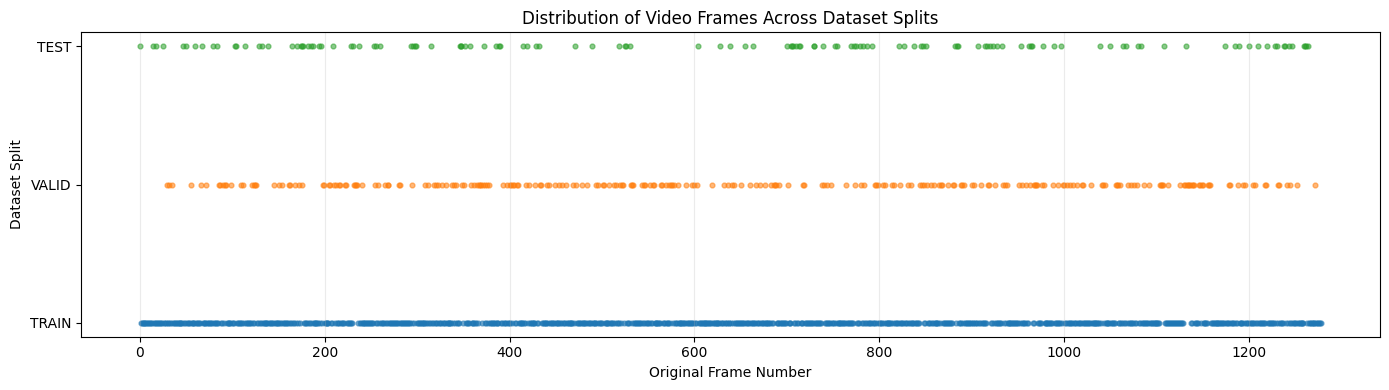


Frame Distribution Analysis: COMPLETE


In [17]:

# Import libraries for dataset analysis and visualization.
# These tools help examine frame sequences and image filename patterns.
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

# Define the existing image metadata file.
# This file was generated during the previous leakage analysis.
METADATA_PATH = (
    PROJECT_DIR / "evaluation_results" /
    "dataset_image_metadata.csv"
)

# Load the previously collected image metadata.
# This avoids recalculating image hashes and frame identifiers.
frame_df = pd.read_csv(METADATA_PATH)

# Confirm that the necessary columns are present.
# Missing metadata must be resolved before continuing.
required_columns = {"split", "filename", "frame_number"}

if not required_columns.issubset(frame_df.columns):
    raise ValueError("Required frame metadata columns are missing.")

# Convert frame numbers into a consistent integer representation.
# This allows numerical sorting and gap analysis.
frame_df["frame_number"] = pd.to_numeric(
    frame_df["frame_number"],
    errors="coerce"
)

# Remove records without recognizable frame numbers.
# These records cannot be included in temporal sequence analysis.
frame_df = frame_df.dropna(
    subset=["frame_number"]
).copy()

frame_df["frame_number"] = frame_df["frame_number"].astype(int)

# Extract the filename prefix appearing before the frame number.
# Prefixes may help identify different video sources, but do not prove them.
frame_df["filename_prefix"] = frame_df["filename"].apply(
    lambda name: (
        re.split(r"frame[_-]\d+", name, maxsplit=1, flags=re.I)[0]
        if re.search(r"frame[_-]\d+", name, flags=re.I)
        else "unrecognized"
    )
)

# Calculate basic frame statistics for each dataset split.
# These reveal how the split ranges overlap.
split_summary = (
    frame_df.groupby("split")
    .agg(
        image_count=("filename", "count"),
        minimum_frame=("frame_number", "min"),
        maximum_frame=("frame_number", "max"),
        unique_frames=("frame_number", "nunique")
    )
    .reset_index()
)

# Display the frame distribution summary.
# Overlapping numerical ranges may indicate interleaved video frames.
print("=" * 75)
print("CO2.2 - VIDEO FRAME DISTRIBUTION ANALYSIS")
print("=" * 75)

print("\nFRAME DISTRIBUTION BY SPLIT")
print(split_summary.to_string(index=False))

# Display filename prefixes and their frequencies.
# This may indicate whether multiple source naming patterns exist.
print("\nFILENAME PREFIX DISTRIBUTION")
print(
    frame_df["filename_prefix"]
    .value_counts()
    .head(15)
    .to_string()
)

# Sort the unique frame numbers across the entire dataset.
# This allows gaps and possible sequence boundaries to be examined.
unique_frames = np.sort(
    frame_df["frame_number"].unique()
)

# Calculate the difference between consecutive frame identifiers.
# Large numerical gaps may indicate missing frames or video boundaries.
frame_gaps = np.diff(unique_frames)

# Display frame continuity statistics.
# These values will help us plan a safer dataset partition.
print("\nFRAME CONTINUITY STATISTICS")
print("Unique Frame IDs:", len(unique_frames))
print("Minimum Frame ID:", unique_frames.min())
print("Maximum Frame ID:", unique_frames.max())

if len(frame_gaps) > 0:

    print("Median Frame Gap:", np.median(frame_gaps))
    print("Maximum Frame Gap:", frame_gaps.max())
    print("Gaps Greater Than 5:", np.sum(frame_gaps > 5))
    print("Gaps Greater Than 20:", np.sum(frame_gaps > 20))

    # Identify the largest discontinuities in frame numbering.
    # These are candidates for further inspection, not confirmed video boundaries.
    gap_table = pd.DataFrame({
        "Frame Before Gap": unique_frames[:-1],
        "Frame After Gap": unique_frames[1:],
        "Gap Size": frame_gaps
    })

    print("\nTOP 10 LARGEST FRAME GAPS")
    print(
        gap_table.sort_values(
            "Gap Size",
            ascending=False
        ).head(10).to_string(index=False)
    )

# Create a visualization showing frame assignment by split.
# This helps identify interleaving across the video timeline.
plt.figure(figsize=(14, 4))

split_order = ["train", "valid", "test"]

for position, split in enumerate(split_order):

    subset = frame_df[
        frame_df["split"] == split
    ]

    # Plot frame identifiers at the corresponding split position.
    # Each point represents an image assigned to that split.
    plt.scatter(
        subset["frame_number"],
        np.full(len(subset), position),
        label=split.upper(),
        alpha=0.55,
        s=12
    )

# Add descriptive axis labels and a figure title.
# The visualization summarizes existing dataset partitioning.
plt.yticks(
    range(len(split_order)),
    [split.upper() for split in split_order]
)

plt.xlabel("Original Frame Number")
plt.ylabel("Dataset Split")
plt.title("Distribution of Video Frames Across Dataset Splits")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

# Save the plot for the final project report.
# This documents the initial temporal partitioning.
output_path = (
    PROJECT_DIR / "visualizations" /
    "frame_distribution_analysis.png"
)

plt.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight"
)

# Display the plot for visual inspection.
# Interleaved points across rows suggest overlapping time ranges.
plt.show()

# Save the frame distribution summary as a CSV file.
# This provides documented evidence for dataset preparation.
split_summary.to_csv(
    PROJECT_DIR / "evaluation_results" /
    "frame_distribution_summary.csv",
    index=False
)

# Confirm that the analysis is complete.
# No changes have been made to the dataset partitions.
print("\nFrame Distribution Analysis: COMPLETE")


## 3.8 Chronological Dataset Partitioning and Temporal Leakage Prevention

This section reorganizes the pedestrian detection dataset using chronological frame ordering to reduce the risk of temporal data leakage during RF-DETR model training and evaluation. The dataset consists of 1,279 consecutively numbered frames extracted from a single video recording. The initial random partition distributed neighboring video frames across training, validation, and testing subsets, potentially introducing correlations that could inflate evaluation performance.

To address this limitation, the images are sorted according to their original frame identifiers and reassigned to chronological training, validation, and testing subsets. The procedure targets a 70% training, 15% validation, and 15% testing distribution while excluding 20-frame temporal buffer zones between adjacent subsets. The excluded frames help reduce direct temporal overlap near partition boundaries. Original images and their corresponding YOLO-format bounding box annotations are preserved, and a separate dataset directory is created to avoid modifying the original files.

The chronological partition provides a more defensible evaluation protocol for sequential video data than the original random split. However, because all frames originate from the same camera recording, the subsets still share environmental characteristics and scene context. Consequently, the final evaluation will measure performance on later unseen frames from the same recording rather than independent generalization to different locations or camera viewpoints.

In [18]:

# Import libraries for file handling, data organization, and analysis.
# These tools allow us to reorganize images without changing their contents.
from pathlib import Path
import pandas as pd
import shutil
import re

# Define the location of the previously validated YOLO dataset.
# This directory will only be read and will not be modified.
SOURCE_DIR = (
    PROJECT_DIR / "dataset_processed" / "pedestrian_dataset"
)

# Define a separate directory for the chronological dataset.
# This prevents the original random-split dataset from being overwritten.
CHRONO_DIR = (
    PROJECT_DIR / "dataset_processed" / "pedestrian_chronological"
)

# Define the dataset splits and the temporal buffer size.
# Twenty frames will be excluded at each of the two boundaries.
SOURCE_SPLITS = ["train", "valid", "test"]
BUFFER_SIZE = 20

# Define the desired proportions of retained images.
# The buffer frames are excluded before calculating these proportions.
TRAIN_RATIO = 0.70
VALID_RATIO = 0.15

# Define supported image formats for the dataset.
# These extensions cover the common image formats used in YOLO datasets.
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Create a collection for original image and annotation paths.
# This reconstructs the complete chronological sequence.
all_records = []

# Read image filenames from all three existing subsets.
# Their original random split assignments will not be reused.
for original_split in SOURCE_SPLITS:

    images_dir = SOURCE_DIR / original_split / "images"
    labels_dir = SOURCE_DIR / original_split / "labels"

    # Examine every supported image in the current directory.
    # Only images with recognizable source frame identifiers are accepted.
    for image_path in sorted(images_dir.iterdir()):

        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        # Extract the frame number from the original image filename.
        # Frame numbers provide the chronological ordering.
        match = re.search(
            r"frame[_-](\d+)",
            image_path.stem,
            flags=re.IGNORECASE
        )

        if match is None:
            raise ValueError(
                f"Frame number not found: {image_path.name}"
            )

        frame_number = int(match.group(1))

        # Locate the corresponding YOLO annotation file.
        # An error is raised if an expected annotation is missing.
        label_path = labels_dir / f"{image_path.stem}.txt"

        if not label_path.is_file():
            raise FileNotFoundError(
                f"Missing annotation: {label_path}"
            )

        # Preserve the source paths and original frame identifier.
        # These records will determine the new split assignments.
        all_records.append({
            "frame_number": frame_number,
            "image_path": image_path,
            "label_path": label_path,
            "original_split": original_split
        })

# Sort all image records according to their original frame number.
# This reconstructs the timeline independently of the random split.
all_records.sort(key=lambda record: record["frame_number"])

# Validate that all original frame identifiers are unique.
# Duplicate identifiers could make chronological assignments ambiguous.
frame_numbers = [record["frame_number"] for record in all_records]

if len(frame_numbers) != len(set(frame_numbers)):
    raise ValueError("Duplicate frame numbers detected.")

# Calculate how many images remain after temporal buffer exclusion.
# Two buffer zones are required between three dataset subsets.
total_images = len(all_records)
excluded_images = BUFFER_SIZE * 2
usable_images = total_images - excluded_images

if usable_images <= 0:
    raise ValueError("Insufficient images after buffer exclusion.")

# Calculate the target training and validation subset sizes.
# Remaining usable images will be assigned to the test subset.
train_count = int(usable_images * TRAIN_RATIO)
valid_count = int(usable_images * VALID_RATIO)
test_count = usable_images - train_count - valid_count

# Determine the chronological partition boundaries.
# Buffer zones are placed between training/validation and validation/test.
train_end = train_count
first_buffer_end = train_end + BUFFER_SIZE
valid_end = first_buffer_end + valid_count
second_buffer_end = valid_end + BUFFER_SIZE

# Assign chronological records to the new subsets.
# Excluded buffer records will not be copied into model-training folders.
assignments = (
    ["train"] * train_count
    + ["buffer_1"] * BUFFER_SIZE
    + ["valid"] * valid_count
    + ["buffer_2"] * BUFFER_SIZE
    + ["test"] * test_count
)

# Verify that every record received exactly one assignment.
# This prevents missing frames or incorrect dataset sizes.
assert len(assignments) == total_images

# Create the new dataset directories.
# The original dataset remains separate and unchanged.
for split in ["train", "valid", "test"]:

    (CHRONO_DIR / split / "images").mkdir(
        parents=True, exist_ok=True
    )

    (CHRONO_DIR / split / "labels").mkdir(
        parents=True, exist_ok=True
    )

# Prepare a manifest documenting every frame assignment.
# This provides traceability for the dataset preparation process.
manifest_records = []

# Copy each retained image together with its YOLO annotation.
# Buffer frames are documented but excluded from the new dataset.
for record, assignment in zip(all_records, assignments):

    # Add the current frame to the assignment manifest.
    # This includes both retained and excluded frames.
    manifest_records.append({
        "frame_number": record["frame_number"],
        "original_split": record["original_split"],
        "new_assignment": assignment,
        "image_filename": record["image_path"].name
    })

    # Skip the buffer images to maintain temporal separation.
    # Their original files remain available in the source dataset.
    if assignment.startswith("buffer"):
        continue

    # Define the destination paths for the image and annotation.
    # Matching filenames preserve the original YOLO label association.
    new_image_path = (
        CHRONO_DIR / assignment / "images"
        / record["image_path"].name
    )

    new_label_path = (
        CHRONO_DIR / assignment / "labels"
        / record["label_path"].name
    )

    # Copy the original image into its chronological split.
    # copy2 preserves file contents and available metadata.
    shutil.copy2(
        record["image_path"],
        new_image_path
    )

    # Copy the corresponding annotation into the same split.
    # No bounding box coordinates are modified.
    shutil.copy2(
        record["label_path"],
        new_label_path
    )

# Copy the original dataset class configuration.
# This preserves the single person class definition.
shutil.copy2(
    SOURCE_DIR / "data.yaml",
    CHRONO_DIR / "data.yaml"
)

# Save the full chronological frame assignment manifest.
# This documents retained and excluded frames for reproducibility.
manifest_df = pd.DataFrame(manifest_records)

manifest_path = (
    PROJECT_DIR / "evaluation_results"
    / "chronological_split_manifest.csv"
)

manifest_df.to_csv(
    manifest_path,
    index=False
)

# Summarize the number and frame range of each partition.
# These statistics will support the final report.
print("=" * 75)
print("CO2.2 - CHRONOLOGICAL DATASET SPLITTING")
print("=" * 75)

print("Original Images:", total_images)
print("Temporal Buffer Size:", BUFFER_SIZE)
print("Total Excluded Buffer Frames:", excluded_images)
print("Usable Images:", usable_images)

# Display the chronological ranges of all five partitions.
# This verifies that train, validation, and test are separated.
for assignment in [
    "train", "buffer_1", "valid", "buffer_2", "test"
]:

    subset = manifest_df[
        manifest_df["new_assignment"] == assignment
    ]

    print(f"\n{assignment.upper()}")
    print("Images:", len(subset))
    print("First Frame:", subset["frame_number"].min())
    print("Last Frame:", subset["frame_number"].max())

# Confirm that the reorganized dataset was saved.
# The following step will verify the copied files.
print("\nChronological Dataset Splitting: COMPLETE")
print("New Dataset Directory:", CHRONO_DIR)
print("Manifest Saved:", manifest_path)


CO2.2 - CHRONOLOGICAL DATASET SPLITTING
Original Images: 1279
Temporal Buffer Size: 20
Total Excluded Buffer Frames: 40
Usable Images: 1239

TRAIN
Images: 867
First Frame: 0
Last Frame: 866

BUFFER_1
Images: 20
First Frame: 867
Last Frame: 886

VALID
Images: 185
First Frame: 887
Last Frame: 1071

BUFFER_2
Images: 20
First Frame: 1072
Last Frame: 1091

TEST
Images: 187
First Frame: 1092
Last Frame: 1278

Chronological Dataset Splitting: COMPLETE
New Dataset Directory: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/dataset_processed/pedestrian_chronological
Manifest Saved: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/evaluation_results/chronological_split_manifest.csv


## 3.9 Verification of Chronological Dataset Integrity

This section verifies the integrity of the chronologically reorganized pedestrian detection dataset following temporal buffer exclusion. The dataset was partitioned into training, validation, and testing subsets using the original video frame identifiers, with 20-frame buffer zones inserted between adjacent subsets to reduce temporal overlap and possible data leakage.

The verification procedure examines the number of images and annotation files, validates YOLO-format bounding box coordinates and object class identifiers, and confirms that frame identifiers do not overlap across dataset subsets. It also checks the chronological separation between training, validation, and testing partitions and summarizes the distribution of annotated pedestrian instances. These checks establish whether the reorganized dataset is structurally suitable for subsequent RF-DETR model training and evaluation.

Although chronological partitioning reduces direct overlap between neighboring video frames, it does not eliminate the shared visual characteristics of images captured from the same camera. This limitation will be considered when interpreting the final model evaluation results.

In [20]:
# Import libraries for dataset validation and reporting.
# These libraries support file inspection, annotation checks, and result summaries.
from pathlib import Path
import pandas as pd
import re
import math
import yaml

# Define the location of the chronological dataset.
# This is the reorganized dataset created in Cell 12.
CHRONO_DIR = (
    PROJECT_DIR / "dataset_processed" /
    "pedestrian_chronological"
)

# Define the expected dataset partitions.
# Only these subsets will be used for training and evaluation.
splits = ["train", "valid", "test"]

# Define supported image extensions.
# These formats will be included in the integrity inspection.
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Initialize collections for statistics and validation issues.
# These will summarize the dataset and identify possible errors.
summary_records = []
validation_errors = []
frame_sets = {}

# Examine the dataset configuration file.
# The expected target is one object class named person.
with open(CHRONO_DIR / "data.yaml", "r", encoding="utf-8") as file:
    config = yaml.safe_load(file)

# Normalize the class definitions into a list.
# This supports both list-based and dictionary-based YOLO configurations.
class_names = config.get("names", [])

if isinstance(class_names, dict):
    class_names = [
        value for key, value in sorted(
            class_names.items(),
            key=lambda item: int(item[0])
        )
    ]

# Verify that the dataset contains only the person class.
# Incorrect class definitions must be resolved before training.
if class_names != ["person"]:
    validation_errors.append(
        f"Unexpected dataset classes: {class_names}"
    )

if config.get("nc", len(class_names)) != 1:
    validation_errors.append(
        "Dataset configuration does not specify one class."
    )

# Inspect all chronological dataset partitions.
# Every image and annotation will be checked for consistency.
for split in splits:

    # Locate the image and annotation directories.
    # These folders must exist for each dataset partition.
    images_dir = CHRONO_DIR / split / "images"
    labels_dir = CHRONO_DIR / split / "labels"

    if not images_dir.is_dir() or not labels_dir.is_dir():
        raise FileNotFoundError(
            f"Missing dataset directory for {split}"
        )

    # Collect images and annotation files.
    # Matching filename stems identify image-label pairs.
    images = sorted([
        path for path in images_dir.iterdir()
        if path.is_file()
        and path.suffix.lower() in image_extensions
    ])

    labels = sorted(labels_dir.glob("*.txt"))

    # Build lookup sets for detecting missing or extra files.
    # This helps identify incomplete dataset transfers.
    image_stems = {path.stem for path in images}
    label_stems = {path.stem for path in labels}

    missing_labels = image_stems - label_stems
    orphan_labels = label_stems - image_stems

    # Record any missing or unmatched annotations.
    # Both conditions indicate dataset integrity problems.
    for stem in sorted(missing_labels):
        validation_errors.append(
            f"{split}: Missing label for {stem}"
        )

    for stem in sorted(orphan_labels):
        validation_errors.append(
            f"{split}: Label without image for {stem}"
        )

    # Initialize annotation statistics for the current split.
    # These counters distinguish objects from empty annotations.
    pedestrian_count = 0
    empty_label_count = 0
    invalid_box_count = 0
    current_frames = set()

    # Process every image and its corresponding annotation.
    # Frame IDs are extracted to verify chronological separation.
    for image_path in images:

        # Extract the source video frame number.
        # All filenames are expected to follow the frame_NNN pattern.
        match = re.search(
            r"frame[_-](\d+)",
            image_path.stem,
            flags=re.IGNORECASE
        )

        if match is None:
            validation_errors.append(
                f"{split}: Missing frame ID in {image_path.name}"
            )
        else:
            frame_id = int(match.group(1))

            if frame_id in current_frames:
                validation_errors.append(
                    f"{split}: Repeated frame ID {frame_id}"
                )

            current_frames.add(frame_id)

        # Locate the annotation corresponding to this image.
        # Missing annotations have already been recorded above.
        label_path = labels_dir / f"{image_path.stem}.txt"

        if not label_path.is_file():
            continue

        # Read the annotation lines.
        # Empty labels are permitted for background-only images.
        lines = label_path.read_text(
            encoding="utf-8"
        ).strip().splitlines()

        if not lines:
            empty_label_count += 1
            continue

        # Validate every annotated bounding box.
        # YOLO labels must contain one class and four normalized values.
        for line_number, line in enumerate(lines, start=1):

            values = line.split()
            valid = False

            # Confirm the expected number of numeric entries.
            # Malformed annotations are rejected.
            if len(values) == 5:

                try:
                    class_id, x, y, w, h = map(float, values)

                    # Verify class identity and normalized box geometry.
                    # Small floating-point tolerances are permitted.
                    valid = (
                        all(math.isfinite(v) for v in
                            [class_id, x, y, w, h])
                        and class_id == 0
                        and 0 <= x <= 1
                        and 0 <= y <= 1
                        and 0 < w <= 1
                        and 0 < h <= 1
                        and x - w / 2 >= -1e-6
                        and x + w / 2 <= 1 + 1e-6
                        and y - h / 2 >= -1e-6
                        and y + h / 2 <= 1 + 1e-6
                    )

                except ValueError:
                    valid = False

            # Count valid pedestrians or record invalid annotations.
            # All detected errors will appear in the final report.
            if valid:
                pedestrian_count += 1
            else:
                invalid_box_count += 1
                validation_errors.append(
                    f"{split}: Invalid box in "
                    f"{label_path.name}, line {line_number}"
                )

    # Store the frame identifiers for cross-split verification.
    # These sets will be compared after processing all partitions.
    frame_sets[split] = current_frames

    # Record the integrity statistics for the current split.
    # These results will be saved for final project documentation.
    summary_records.append({
        "Split": split,
        "Images": len(images),
        "Label Files": len(labels),
        "Pedestrian Instances": pedestrian_count,
        "Empty Labels": empty_label_count,
        "Invalid Boxes": invalid_box_count,
        "First Frame": min(current_frames) if current_frames else None,
        "Last Frame": max(current_frames) if current_frames else None
    })

# Confirm that frame identifiers are unique across subsets.
# Shared frame IDs would indicate incorrect partitioning.
for index, split_a in enumerate(splits):

    for split_b in splits[index + 1:]:

        overlap = frame_sets[split_a] & frame_sets[split_b]

        if overlap:
            validation_errors.append(
                f"Frame overlap between {split_a} and {split_b}: "
                f"{len(overlap)} frames"
            )

# Verify the chronological ordering of the partitions.
# Buffer zones should separate their frame-number ranges.
for earlier, later in [("train", "valid"), ("valid", "test")]:

    gap = min(frame_sets[later]) - max(frame_sets[earlier]) - 1

    if gap < 20:
        validation_errors.append(
            f"Insufficient temporal buffer between "
            f"{earlier} and {later}: {gap} frames"
        )

# Create a summary table of dataset integrity results.
# This table documents the final dataset composition.
summary_df = pd.DataFrame(summary_records)

# Display the dataset verification summary.
# This allows us to review the retained training and testing data.
print("=" * 85)
print("CO2.2 - CHRONOLOGICAL DATASET INTEGRITY REPORT")
print("=" * 85)
print(summary_df.to_string(index=False))

# Display the number of detected integrity problems.
# Ideally, the verification should produce zero errors.
print("\nTotal Validation Errors:", len(validation_errors))

# Display example errors when problems are detected.
# The original dataset will remain unchanged.
if validation_errors:

    print("\nFirst 20 Errors:")

    for error in validation_errors[:20]:
        print("-", error)

else:
    print("\nAll structural and annotation checks passed.")

# Save the integrity summary and complete error log.
# These CSV files can be included in the GitHub repository.
RESULTS_DIR = PROJECT_DIR / "evaluation_results"

summary_df.to_csv(
    RESULTS_DIR / "chronological_dataset_integrity.csv",
    index=False
)

pd.DataFrame({
    "error": validation_errors
}).to_csv(
    RESULTS_DIR / "chronological_integrity_errors.csv",
    index=False
)

# Report the final dataset verification status.
# Training should proceed only after validation errors are resolved.
if len(validation_errors) == 0:
    print("\nChronological Dataset Verification: PASSED")
else:
    print("\nChronological Dataset Verification: NEEDS REVIEW")


CO2.2 - CHRONOLOGICAL DATASET INTEGRITY REPORT
Split  Images  Label Files  Pedestrian Instances  Empty Labels  Invalid Boxes  First Frame  Last Frame
train     867          867                  2617            16              0            0         866
valid     185          185                   466            11              0          887        1071
 test     187          187                   535            11              0         1092        1278

Total Validation Errors: 0

All structural and annotation checks passed.

Chronological Dataset Verification: PASSED


## 4.1 Preparation of Dataset Configuration for RF-DETR

This section prepares the verified chronological pedestrian detection dataset for integration with the RF-DETR object detection framework. The dataset consists of 1,239 retained images divided into training, validation, and testing subsets, with temporal buffer zones separating the partitions to reduce the risk of data leakage. All images are accompanied by YOLO-format bounding box annotations representing the person object class.

The procedure generates a standardized dataset configuration file containing the training, validation, and testing directory paths, the number of object classes, and the corresponding class names. The configuration follows the YOLO dataset structure supported by RF-DETR, allowing the framework to automatically recognize the dataset during model training. The code also verifies the required directories and configuration settings to ensure compatibility before model initialization.

Using the existing YOLO annotations avoids unnecessary format conversion and preserves the validated bounding box coordinates. Image resizing, normalization, and applicable training augmentations will be handled through the RF-DETR training pipeline, while the testing subset will remain reserved for final model evaluation.

In [21]:

# Import libraries for dataset configuration and validation.
# These tools allow us to create YAML files and manage dataset paths.
from pathlib import Path
import yaml

# Import RF-DETR's dataset discovery utilities.
# These helpers locate YOLO configuration files and training images.
from rfdetr.datasets import find_yolo_data_file, find_yolo_train_images

# Define the verified chronological dataset directory.
# This dataset will be used for RF-DETR training and evaluation.
RFDETR_DATASET_DIR = (
    PROJECT_DIR / "dataset_processed" /
    "pedestrian_chronological"
)

# Define the dataset configuration file location.
# RF-DETR uses this file to identify the dataset structure.
DATA_YAML_PATH = RFDETR_DATASET_DIR / "data.yaml"

# Define the configuration for pedestrian-only detection.
# The dataset contains one object class with class identifier zero.
dataset_config = {
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 1,
    "names": ["person"]
}

# Save the configuration using standard YAML formatting.
# This ensures the dataset paths are relative to the dataset directory.
with open(DATA_YAML_PATH, "w", encoding="utf-8") as file:
    yaml.safe_dump(
        dataset_config,
        file,
        sort_keys=False
    )

# Read back the saved configuration.
# This verifies that the written YAML file is accessible.
with open(DATA_YAML_PATH, "r", encoding="utf-8") as file:
    verified_config = yaml.safe_load(file)

# Display the final dataset configuration.
# These settings will be used during RF-DETR training.
print("=" * 65)
print("CO2.2 - RF-DETR DATASET CONFIGURATION")
print("=" * 65)

print(yaml.safe_dump(
    verified_config,
    sort_keys=False
))

# Verify the expected dataset directories.
# Missing directories must be corrected before model training.
for split in ["train", "valid", "test"]:

    images_dir = RFDETR_DATASET_DIR / split / "images"
    labels_dir = RFDETR_DATASET_DIR / split / "labels"

    assert images_dir.is_dir(), f"Missing images directory: {images_dir}"
    assert labels_dir.is_dir(), f"Missing labels directory: {labels_dir}"

    print(f"{split.upper()} Directories: VERIFIED")

# Verify the number and name of object classes.
# The model must be configured for pedestrian-only detection.
assert verified_config["nc"] == 1
assert verified_config["names"] == ["person"]

# Use the official RF-DETR helpers to locate the dataset.
# Successful discovery confirms its recognizable YOLO structure.
detected_yaml = find_yolo_data_file(RFDETR_DATASET_DIR)
detected_train_images = find_yolo_train_images(RFDETR_DATASET_DIR)

# Verify the discovered dataset paths.
# A failure indicates that the dataset configuration needs correction.
assert detected_yaml is not None, "RF-DETR could not find data.yaml"
assert detected_train_images is not None, "RF-DETR could not find training images"

# Display the detected dataset locations.
# These confirm the paths that RF-DETR will use.
print("\nRF-DETR Dataset Detection: SUCCESS")
print("Detected YAML:", detected_yaml)
print("Detected Training Images:", detected_train_images)

# Confirm that dataset preparation is complete.
# The project can proceed to model initialization.
print("\nRF-DETR Dataset Configuration: COMPLETE")


CO2.2 - RF-DETR DATASET CONFIGURATION
train: train/images
val: valid/images
test: test/images
nc: 1
names:
- person

TRAIN Directories: VERIFIED
VALID Directories: VERIFIED
TEST Directories: VERIFIED

RF-DETR Dataset Detection: SUCCESS
Detected YAML: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/dataset_processed/pedestrian_chronological/data.yaml
Detected Training Images: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/dataset_processed/pedestrian_chronological/train/images

RF-DETR Dataset Configuration: COMPLETE


## 4.2 RF-DETR Model Initialization and Architecture Inspection

This section initializes the RF-DETR Small object detection model using the official RF-DETR framework and pretrained model weights. RF-DETR is a transformer-based object detection architecture designed to predict object categories and bounding box coordinates. The pretrained model provides an established starting point for transfer learning, reducing the computational requirements compared with training an object detector entirely from random initialization.

The implementation uses PyTorch and the RFDETRSmall model variant to accommodate the computational resources available in Google Colab. The initialization procedure verifies the model configuration, identifies the selected architecture, and examines its available parameters. The pretrained classification head will subsequently be adapted during fine-tuning to detect the single target class, person, using the prepared pedestrian dataset.

The initialized model will serve as the foundation for subsequent training, optimization, and evaluation. Its architecture and configuration will be documented to support reproducibility and explain the model components used in the final project.

In [22]:

# Import PyTorch to verify GPU availability.
# The GPU will be used during subsequent RF-DETR training.
import torch

# Import the RF-DETR Small architecture.
# This variant balances model capability and computational requirements.
from rfdetr import RFDETRSmall

# Import package metadata for reproducibility.
# This records the installed RF-DETR software version.
from importlib.metadata import version

# Confirm that CUDA is available before model initialization.
# Training on the Tesla T4 will be substantially faster than CPU training.
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is not available.")

# Display the GPU and RF-DETR package information.
# These details will be included in the project methodology.
print("=" * 65)
print("CO2.2 - RF-DETR MODEL INITIALIZATION")
print("=" * 65)

print("PyTorch Version:", torch.__version__)
print("RF-DETR Version:", version("rfdetr"))
print("GPU:", torch.cuda.get_device_name(0))

# Initialize RF-DETR Small using its pretrained checkpoint.
# Pretrained weights provide a starting point for fine-tuning.
model = RFDETRSmall()

# Retrieve the current architecture configuration.
# The configuration describes the model before dataset-specific training.
model_config = model.model_config

# Display the configured model type.
# RF-DETR Small will be used for the initial training experiment.
print("\nModel Variant: RFDETRSmall")

# Display the available architecture configuration.
# These values document the initialized model's characteristics.
print("\nMODEL CONFIGURATION")
print(model_config)

# Inspect the initialized model's available parameter tensors.
# This allows us to estimate the parameter count without training.
model_context = model.model

# Identify the underlying PyTorch model.
# RF-DETR wraps its neural network inside a model context.
network = model_context.model

# Calculate the total number of model parameters.
# This indicates the approximate size of the neural network.
total_parameters = sum(
    parameter.numel()
    for parameter in network.parameters()
)

# Calculate the number of currently trainable parameters.
# Some components may be frozen during particular training stages.
trainable_parameters = sum(
    parameter.numel()
    for parameter in network.parameters()
    if parameter.requires_grad
)

# Display the parameter counts.
# These values can be used in the RF-DETR model description.
print("\nMODEL PARAMETER SUMMARY")
print(f"Total Parameters: {total_parameters:,}")
print(f"Trainable Parameters: {trainable_parameters:,}")

# Display the existing pretrained classification configuration.
# The final pedestrian-specific class setup will occur during training.
print("\nInitial Class Configuration:",
      model_config.num_classes)

# Confirm that the pretrained model is initialized successfully.
# Model training will begin only after reviewing these results.
print("\nRF-DETR Model Initialization: COMPLETE")


CO2.2 - RF-DETR MODEL INITIALIZATION
PyTorch Version: 2.11.0+cu130
RF-DETR Version: 1.11.2
GPU: Tesla T4
[2026-10-11 20:32:41] [INFO] rf-detr - Downloading pretrained weights for /root/.roboflow/models/rf-detr-small.pth


/root/.roboflow/models/rf-detr-small.pth:   0%|          | 0.00/368M [00:00<?, ?iB/s]

[2026-10-11 20:32:49] [INFO] rf-detr - MD5 validation successful for /root/.roboflow/models/rf-detr-small.pth


[2026-10-11 20:32:49] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-11 20:32:49] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-11 20:32:50] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-small.pth already exists with correct MD5 hash.

Model Variant: RFDETRSmall

MODEL CONFIGURATION
encoder='dinov2_windowed_small' out_feature_indexes=[3, 6, 9, 12] dec_layers=3 two_stage=True projector_scale=['P4'] hidden_dim=256 patch_size=16 num_windows=2 sa_nheads=8 ca_nheads=16 dec_n_points=2 num_queries=300 num_select=300 postprocess_trace_alpha=0.2 bbox_reparam=True lite_refpoint_refine=True layer_norm=True amp=True num_channels=3 num_classes=90 pretrain_weights='/root/.roboflow/models/rf-detr-small.pth' device='cuda' resolution=512 group_detr=13 gradient_checkpointing=False compile=False cuda_graphs=False fused_optimizer=True positional_encoding_size=32 ia_bce_loss=True segmentation_head=False use_grouppose_keypoints=False keypoint_cross_attn=True inter_instance_kp_attn=False grouppose_keypoint_dim_downscale=1 dual_projector=False dual_projector_kp_only=False num_keypoints_per_class=[] num_decoder_register

## 5.1 Training Configuration and Hyperparameter Selection

This section establishes the training configuration for fine-tuning the pretrained RF-DETR Small model on the chronological pedestrian detection dataset. The training procedure uses PyTorch with GPU acceleration and applies transfer learning to adapt the pretrained object detector to the single person object class. The configuration considers the available Tesla T4 GPU resources, dataset size, and requirements for reproducible model evaluation.

The selected hyperparameters include the maximum number of training epochs, batch size, gradient accumulation steps, learning rate, and early stopping settings. Gradient accumulation is used to maintain a larger effective batch size while reducing the number of images processed simultaneously in GPU memory. Early stopping monitors validation detection performance and terminates training when the selected metric no longer improves for a specified number of validation epochs. The training process also saves model checkpoints and performance logs for subsequent evaluation.

The initial experiment is configured for a maximum of 20 epochs, using a physical batch size of four images, four gradient accumulation steps, and a learning rate of 0.0001. These values represent an initial experimental configuration rather than a confirmed optimal solution. The validation subset will be used to assess training progress, while the testing subset will remain reserved for final evaluation. The resulting training parameters will be documented to support reproducibility and subsequent optimization experiments.

In [23]:
# Import libraries for training configuration and file storage.
# These allow us to define settings and save them for reproducibility.
from pathlib import Path
import json
import torch

# Define the verified chronological pedestrian dataset.
# This dataset contains training, validation, and test subsets.
TRAIN_DATASET_DIR = (
    PROJECT_DIR / "dataset_processed" /
    "pedestrian_chronological"
)

# Define the directory for the first RF-DETR training experiment.
# Saving each experiment separately prevents checkpoint confusion.
TRAIN_OUTPUT_DIR = (
    PROJECT_DIR / "training_outputs" /
    "rfdetr_small_baseline"
)

# Create the training output directory.
# Model checkpoints and logs will be saved here.
TRAIN_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Define the initial training hyperparameters.
# These settings will be passed to the official RF-DETR trainer.
training_config = {
    "dataset_dir": str(TRAIN_DATASET_DIR),
    "output_dir": str(TRAIN_OUTPUT_DIR),
    "epochs": 20,
    "batch_size": 4,
    "grad_accum_steps": 4,
    "lr": 0.0001,
    "early_stopping": True,
    "early_stopping_patience": 7,
    "early_stopping_min_delta": 0.001,
    "best_model_metric": "map",
    "run_test": False
}

# Confirm that CUDA remains available.
# RF-DETR training will use the allocated NVIDIA GPU.
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is not available.")

# Confirm that the required training dataset exists.
# Missing data must be resolved before the training process starts.
if not (TRAIN_DATASET_DIR / "train" / "images").is_dir():
    raise FileNotFoundError("Training images directory not found.")

# Confirm that validation images are available.
# RF-DETR uses validation results for model selection and early stopping.
if not (TRAIN_DATASET_DIR / "valid" / "images").is_dir():
    raise FileNotFoundError("Validation images directory not found.")

# Calculate the effective batch size on the single Tesla T4.
# Gradient accumulation combines updates across multiple mini-batches.
effective_batch_size = (
    training_config["batch_size"]
    * training_config["grad_accum_steps"]
)

# Display the training parameters for inspection.
# These values will be documented in the final project report.
print("=" * 70)
print("CO2.2 - RF-DETR TRAINING CONFIGURATION")
print("=" * 70)

for parameter, value in training_config.items():
    print(f"{parameter}: {value}")

# Display the effective batch size separately.
# This represents the nominal batch size for optimizer updates.
print("\nEffective Batch Size:", effective_batch_size)
print("GPU:", torch.cuda.get_device_name(0))

# Save the experiment configuration as a JSON file.
# This preserves the hyperparameters for future experiments.
config_path = TRAIN_OUTPUT_DIR / "training_config.json"

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(
        training_config,
        file,
        indent=4
    )

# Confirm that the configuration has been saved.
# Training can begin after reviewing the printed settings.
print("\nTraining Configuration: COMPLETE")
print("Configuration Saved:", config_path)


CO2.2 - RF-DETR TRAINING CONFIGURATION
dataset_dir: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/dataset_processed/pedestrian_chronological
output_dir: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/training_outputs/rfdetr_small_baseline
epochs: 20
batch_size: 4
grad_accum_steps: 4
lr: 0.0001
early_stopping: True
early_stopping_patience: 7
early_stopping_min_delta: 0.001
best_model_metric: map
run_test: False

Effective Batch Size: 16
GPU: Tesla T4

Training Configuration: COMPLETE
Configuration Saved: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/training_outputs/rfdetr_small_baseline/training_config.json


## 5.2 RF-DETR Model Training and Fine-Tuning

This section performs transfer learning using the pretrained RF-DETR Small object detection model on the chronologically partitioned pedestrian dataset. The training procedure adapts the pretrained object detector to recognize and localize pedestrians represented by the single person class. Fine-tuning is performed using GPU acceleration in Google Colab to improve computational efficiency while preserving the benefits of the pretrained model's learned visual representations.

The training process uses a maximum of 20 epochs, a physical batch size of four images, four gradient accumulation steps, and an initial learning rate of 0.0001. RF-DETR's built-in training pipeline manages model optimization, object detection losses, training-time preprocessing and augmentation, validation, and checkpoint generation. Early stopping is enabled to monitor validation mean Average Precision (mAP), with a patience of seven validation epochs and a minimum improvement threshold of 0.001.

Training performance is evaluated using the validation subset, while the independent chronological test partition remains excluded from model selection and optimization. Model checkpoints and training outputs are stored for subsequent performance evaluation, visualization, and comparison. The resulting training logs will provide evidence for analyzing model convergence, generalization, and the effectiveness of the selected hyperparameters.

In [24]:
# Import PyTorch to verify that GPU acceleration is available.
# RF-DETR training requires substantial computational resources.
import torch

# Verify that the Tesla T4 GPU remains accessible.
# Stop the training process if the GPU is unavailable.
if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU unavailable. Enable T4 GPU in Colab runtime settings."
    )

# Confirm that the pretrained RF-DETR model is initialized.
# The model was previously created in Cell 15.
if "model" not in globals():
    raise RuntimeError(
        "RF-DETR model not found. Run Cell 15 first."
    )

# Confirm that the training configuration is available.
# These hyperparameters were defined and saved in Cell 16.
if "training_config" not in globals():
    raise RuntimeError(
        "Training configuration not found. Run Cell 16 first."
    )

# Display the training experiment details.
# These values document the selected model and dataset.
print("=" * 75)
print("CO2.2 - RF-DETR SMALL TRAINING")
print("=" * 75)

print("Model: RF-DETR Small")
print("Dataset:", training_config["dataset_dir"])
print("Maximum Epochs:", training_config["epochs"])
print("Batch Size:", training_config["batch_size"])
print("Gradient Accumulation:", training_config["grad_accum_steps"])
print("Learning Rate:", training_config["lr"])
print("GPU:", torch.cuda.get_device_name(0))

# Begin fine-tuning the pretrained RF-DETR Small model.
# The trainer handles optimization, validation, and checkpoint generation.
model.train(
    dataset_dir=training_config["dataset_dir"],
    output_dir=training_config["output_dir"],
    epochs=training_config["epochs"],
    batch_size=training_config["batch_size"],
    grad_accum_steps=training_config["grad_accum_steps"],
    lr=training_config["lr"],
    early_stopping=training_config["early_stopping"],
    early_stopping_patience=training_config["early_stopping_patience"],
    early_stopping_min_delta=training_config["early_stopping_min_delta"],
    best_model_metric=training_config["best_model_metric"],
    run_test=training_config["run_test"]
)

# Display a confirmation after the training procedure finishes.
# Checkpoints and metrics should now be available for evaluation.
print("\n" + "=" * 75)
print("RF-DETR TRAINING: COMPLETE")
print("=" * 75)

# Display the output directory containing training artifacts.
# These files will be used during evaluation and report preparation.
print("Training Results:", training_config["output_dir"])


CO2.2 - RF-DETR SMALL TRAINING
Model: RF-DETR Small
Dataset: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/dataset_processed/pedestrian_chronological
Maximum Epochs: 20
Batch Size: 4
Gradient Accumulation: 4
Learning Rate: 0.0001
GPU: Tesla T4


[2026-10-11 20:34:19] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-11 20:34:19] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-11 20:34:20] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-small.pth already exists with correct MD5 hash.


[2026-10-11 20:34:22] [WARNING] rf-detr - Checkpoint has 90 classes but model is configured for 1. The detection head will be re-initialized to 1 classes.
INFO:pytorch_lightning.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/usr/local/lib/python3.13/dist-packages/lightning_fabric/loggers/csv_logs.py:268: Experiment logs directory /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/training_outputs/rfdetr_small_baseline/ exists and is not empty. Previous log files in this directory will be deleted when the new ones are saved!


[2026-10-11 20:34:26] [INFO] rf-detr - Using multi-scale training with square resize and scales: [672]
[2026-10-11 20:34:26] [INFO] rf-detr - Built 1 Albumentations transforms from config
[2026-10-11 20:34:26] [INFO] rf-detr - Built 1 Albumentations transforms from config
creating index...
index created!
[2026-10-11 20:34:29] [INFO] rf-detr - Using multi-scale training with square resize and scales: [672]
creating index...
index created!


...

[2026-10-11 20:57:27] [INFO] rf-detr - Best EMA metric improved to 0.3704 (epoch 12)


INFO:pytorch_lightning.callbacks.early_stopping:Metric __rfdetr_effective_map__ improved by 0.002 >= min_delta = 0.001. New best score: 0.372


[2026-10-11 20:59:47] [INFO] rf-detr - Best EMA metric improved to 0.3723 (epoch 13)
[2026-10-11 21:08:48] [INFO] rf-detr - Best EMA metric improved to 0.3725 (epoch 17)
[2026-10-11 21:11:06] [INFO] rf-detr - Best EMA metric improved to 0.3729 (epoch 18)


INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=20` reached.


[2026-10-11 21:14:19] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.0000, ema=0.3729)

RF-DETR TRAINING: COMPLETE
Training Results: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/training_outputs/rfdetr_small_baseline


## 5.3 Training Output Inspection and Model Checkpoint Verification

This section examines the training outputs generated after fine-tuning the RF-DETR Small model for 20 epochs using the chronological pedestrian detection dataset. The model was trained with GPU acceleration, mixed-precision computation, and validation-based checkpoint selection. The training procedure successfully completed the configured maximum number of epochs and saved its best-performing exponential moving average (EMA) model based on validation performance.

The procedure identifies the generated model checkpoints, training logs, configuration files, and evaluation records. It verifies the availability and sizes of saved model weights and examines recorded training metrics to support subsequent analysis of model convergence and performance. The best available checkpoint will be selected for final evaluation using the reserved test dataset.

Checkpoint verification is essential for ensuring that the trained RF-DETR model can be restored and evaluated without repeating the training process. The resulting checkpoint inventory and training records will also support experimental reproducibility, model documentation, and preparation of the final project report.

In [25]:

# Import libraries for model checkpoint inspection and data analysis.
# These allow us to locate training artifacts and read metric records.
from pathlib import Path
import pandas as pd

# Define the output directory of the completed training experiment.
# All checkpoints and training records will be inspected here.
TRAIN_OUTPUT_DIR = (
    PROJECT_DIR / "training_outputs" /
    "rfdetr_small_baseline"
)

# Confirm that the training directory exists.
# Missing output files must be investigated before final evaluation.
if not TRAIN_OUTPUT_DIR.is_dir():
    raise FileNotFoundError(
        f"Training output directory not found: {TRAIN_OUTPUT_DIR}"
    )

# Search for saved model checkpoints.
# RF-DETR may produce PTH and Lightning CKPT files.
checkpoint_files = sorted(
    path for path in TRAIN_OUTPUT_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() in {".pth", ".ckpt"}
)

# Search for training metric CSV files.
# These may contain epoch losses, validation metrics, and learning rates.
metric_files = sorted(
    path for path in TRAIN_OUTPUT_DIR.rglob("metrics.csv")
    if path.is_file()
)

# Display the training artifact summary.
# This confirms what files were generated by RF-DETR.
print("=" * 75)
print("CO2.2 - RF-DETR TRAINING OUTPUT INSPECTION")
print("=" * 75)

print("\nMODEL CHECKPOINTS")

# Display checkpoint filenames and sizes.
# File sizes help identify whether checkpoints were saved successfully.
for checkpoint in checkpoint_files:

    size_mb = checkpoint.stat().st_size / (1024 ** 2)

    print(
        f"{checkpoint.relative_to(TRAIN_OUTPUT_DIR)} "
        f"| {size_mb:.2f} MB"
    )

# Identify the checkpoint selected for final model inference.
# RF-DETR normally saves the best-performing model using this filename.
BEST_CHECKPOINT = (
    TRAIN_OUTPUT_DIR / "checkpoint_best_total.pth"
)

# Confirm whether the selected checkpoint exists.
# Final evaluation should not proceed without trained model weights.
print("\nBEST CHECKPOINT VERIFICATION")

if BEST_CHECKPOINT.is_file():
    print("Best Checkpoint: FOUND")
    print("Checkpoint Path:", BEST_CHECKPOINT)
else:
    print("Best Checkpoint: NOT FOUND")
    print("Review the checkpoint inventory above.")

# Display the discovered training metric files.
# These will be used to create training performance graphs.
print("\nTRAINING METRIC FILES")

for metric_path in metric_files:
    print(metric_path.relative_to(TRAIN_OUTPUT_DIR))

# Load the latest available metric CSV for inspection.
# Missing values are expected when different metrics are logged at different steps.
if metric_files:

    # Select the most recently modified metric log.
    # This is useful when the training directory contains multiple log versions.
    METRICS_PATH = max(
        metric_files,
        key=lambda path: path.stat().st_mtime
    )

    # Read the training metrics into a DataFrame.
    # The original CSV file will not be modified.
    metrics_df = pd.read_csv(METRICS_PATH)

    # Display the available metric column names.
    # These identify which statistics can be analyzed later.
    print("\nAVAILABLE METRIC COLUMNS")

    for column in metrics_df.columns:
        print("-", column)

    # Display the final five recorded metric rows.
    # These provide a preliminary view of the completed experiment.
    print("\nLAST FIVE METRIC ROWS")
    print(metrics_df.tail(5).to_string(index=False))

else:
    print("\nNo metrics.csv file was found.")
    print("We will inspect alternative training logs if needed.")

# Confirm that the output inspection has completed.
# The checkpoint and metric paths will guide the next analysis.
print("\nTraining Output Inspection: COMPLETE")


CO2.2 - RF-DETR TRAINING OUTPUT INSPECTION

MODEL CHECKPOINTS
checkpoint_19.ckpt | 485.89 MB
checkpoint_9.ckpt | 485.89 MB
checkpoint_best_ema.pth | 121.59 MB
checkpoint_best_total.pth | 121.58 MB
last.ckpt | 485.89 MB
last_ema.pth | 121.58 MB

BEST CHECKPOINT VERIFICATION
Best Checkpoint: FOUND
Checkpoint Path: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/training_outputs/rfdetr_small_baseline/checkpoint_best_total.pth

TRAINING METRIC FILES
metrics.csv

AVAILABLE METRIC COLUMNS
- epoch
- step
- train/cardinality_error
- train/cardinality_error_0
- train/cardinality_error_1
- train/cardinality_error_enc
- train/class_error
- train/loss
- train/loss_bbox
- train/loss_bbox_aux
- train/loss_ce
- train/loss_ce_aux
- train/loss_giou
- train/loss_giou_aux
- train/lr
- train/lr_max
- train/lr_min
- val/F1
- val/ema_mAP_50
- val/ema_mAP_50_95
- val/ema_mAP_75
- val/ema_mAR
- val/mAP_50
- val/mAP_50_95
- val/mAP_75
- val/mAR
- val/precision
- val/recall

LAST FIVE METRIC ROWS
 epoch  ste

## 5.4 Training Convergence and Validation Performance Analysis

This section analyzes the convergence behavior and validation performance of the RF-DETR Small pedestrian detection model after completing 20 training epochs. Training convergence analysis is performed to determine whether the model progressively reduced its optimization loss while improving its ability to detect and localize pedestrian objects. The evaluation uses the recorded training and validation metrics generated by the RF-DETR training framework.

The procedure extracts training loss, validation mean Average Precision (mAP), precision, recall, F1 score, and learning rate values from the training metrics CSV file. Since the training framework records different metrics at separate logging steps, the data is organized by epoch and missing values are handled independently for each metric. The processed results are visualized using line graphs to illustrate changes in model performance throughout training.

Training loss is examined to assess optimization progress, while validation mAP@0.50 and mAP@0.50:0.95 measure pedestrian detection performance at different Intersection over Union thresholds. Precision, recall, and F1 score provide additional information about detection reliability and missed objects. Learning rate progression is also analyzed to document the optimization schedule. The resulting figures and numerical summaries will be used to interpret the model's convergence, identify possible performance limitations, and support the discussion of training outcomes in the final project report.

CO2.2 - RF-DETR TRAINING PERFORMANCE ANALYSIS
Recorded Epochs: 20
Metric Columns: 12
Processed Metrics Saved: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/evaluation_results/rfdetr_epoch_metrics.csv


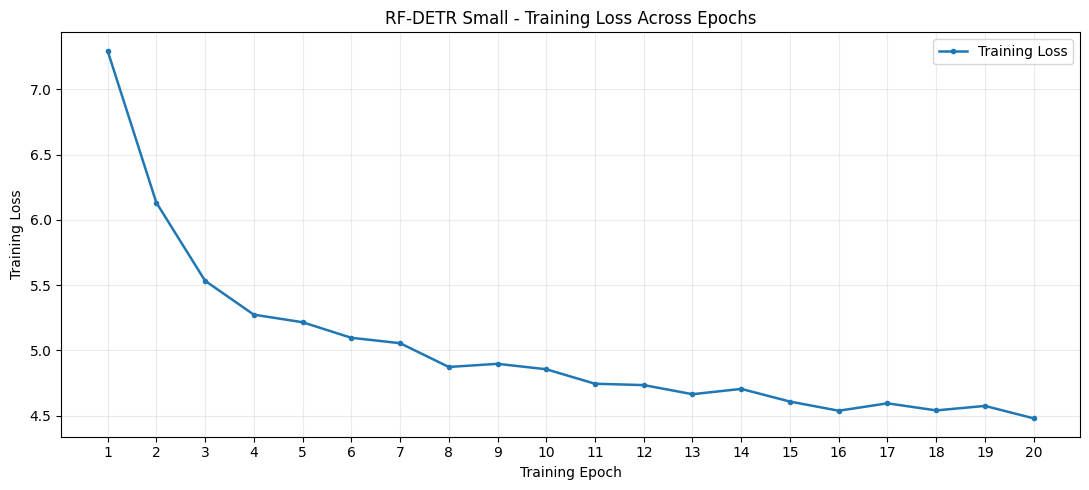

Saved: rfdetr_training_loss.png


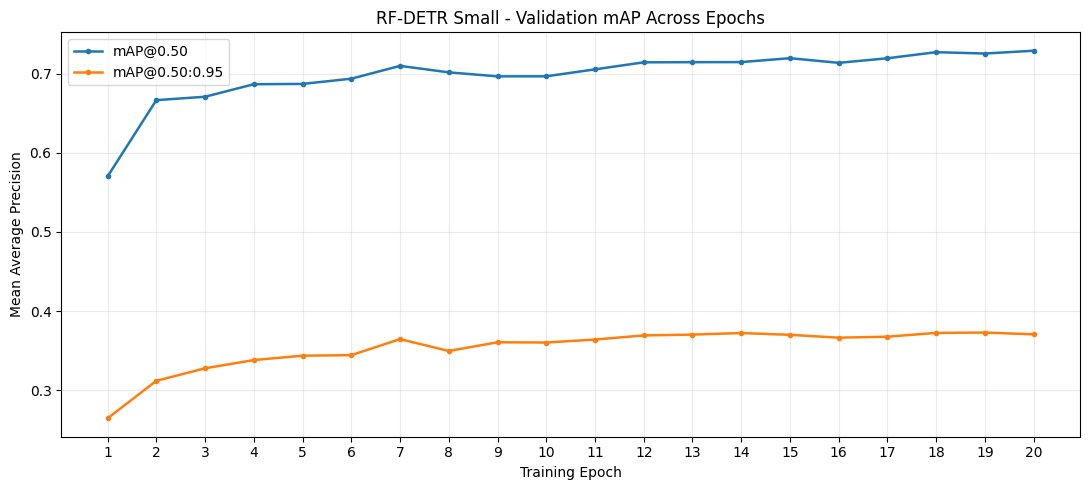

Saved: rfdetr_validation_map.png


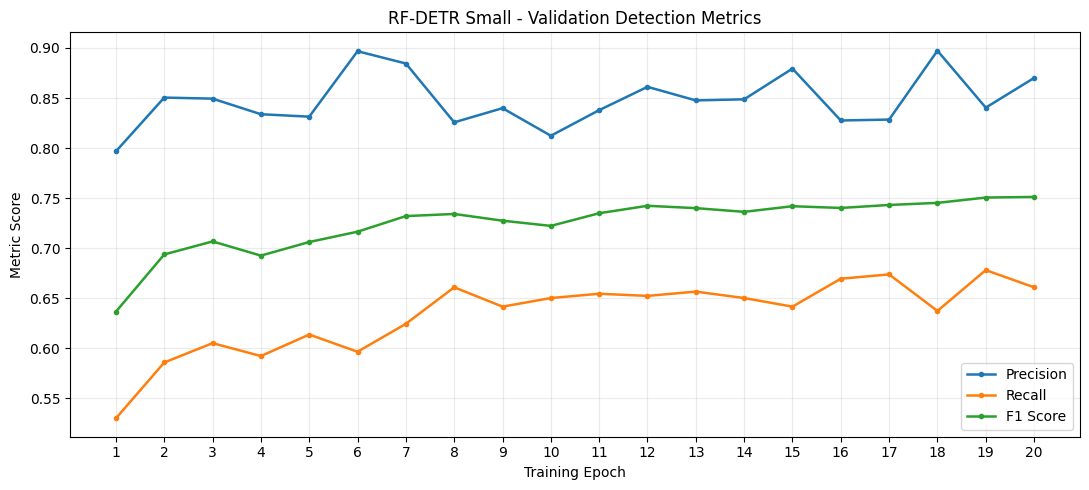

Saved: rfdetr_precision_recall_f1.png


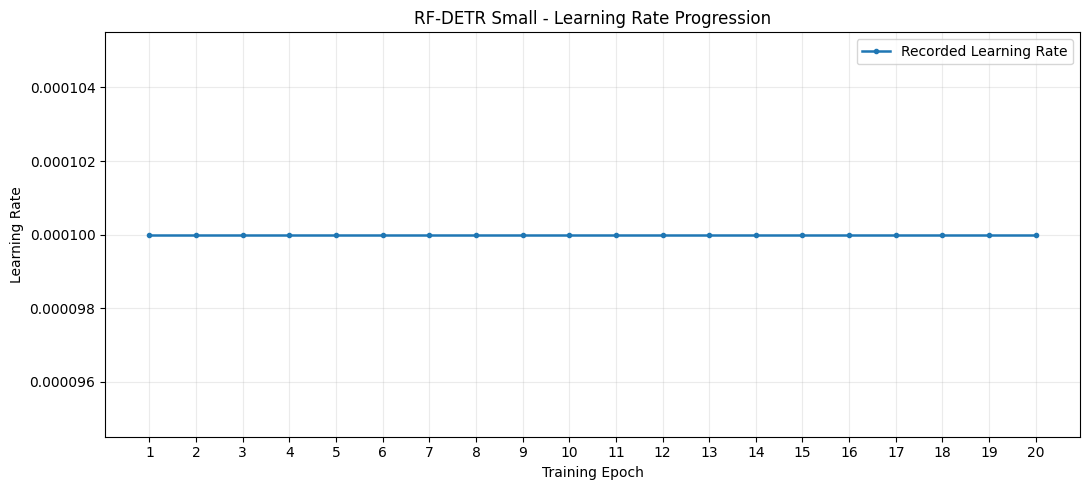

Saved: rfdetr_learning_rate.png

BEST RECORDED VALIDATION PERFORMANCE
Epoch: 19
mAP@0.50:0.95: 0.3729

FINAL RECORDED EPOCH METRICS
 Epoch  train/loss  train/loss_bbox  train/loss_ce  train/loss_giou  train/lr  val/mAP_50  val/mAP_50_95  val/mAP_75  val/ema_mAP_50_95  val/precision  val/recall  val/F1
    20    4.478819         0.009837       0.608684         0.218093    0.0001    0.729057        0.37066    0.330662            0.37066       0.870057    0.660944 0.75122

Training Performance Visualization: COMPLETE


In [26]:

# Import libraries for training metric analysis.
# These support tabular processing and performance visualization.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Define the location of the completed RF-DETR training logs.
# The original metrics file will be read without modification.
TRAIN_OUTPUT_DIR = (
    PROJECT_DIR / "training_outputs" /
    "rfdetr_small_baseline"
)

# Define the CSV containing training and validation metrics.
# This file was identified during the checkpoint inspection.
METRICS_PATH = TRAIN_OUTPUT_DIR / "metrics.csv"

# Define the destination for training performance figures.
# These visualizations will be used in the final PDF report.
VISUALIZATION_DIR = PROJECT_DIR / "visualizations"
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

# Define the destination for processed numerical summaries.
# The results will be saved for reproducibility and reporting.
RESULTS_DIR = PROJECT_DIR / "evaluation_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Verify that the recorded training metrics exist.
# Missing files must be resolved before plotting.
if not METRICS_PATH.is_file():
    raise FileNotFoundError(f"Metrics file not found: {METRICS_PATH}")

# Load the recorded training metrics.
# PyTorch Lightning may log different metrics in separate rows.
metrics_df = pd.read_csv(METRICS_PATH)

# Verify the presence of the epoch column.
# Epoch numbers are required for organizing performance trends.
if "epoch" not in metrics_df.columns:
    raise ValueError("The metrics CSV does not contain an epoch column.")

# Convert epoch identifiers into numeric values.
# Add one to display human-readable epoch numbers starting at 1.
metrics_df["epoch"] = pd.to_numeric(
    metrics_df["epoch"],
    errors="coerce"
)

metrics_df = metrics_df.dropna(
    subset=["epoch"]
).copy()

metrics_df["Epoch"] = metrics_df["epoch"].astype(int) + 1

# Define the training and validation metrics to analyze.
# These columns were verified in the previous inspection.
metric_columns = [
    "train/loss",
    "train/loss_bbox",
    "train/loss_ce",
    "train/loss_giou",
    "train/lr",
    "val/mAP_50",
    "val/mAP_50_95",
    "val/mAP_75",
    "val/ema_mAP_50_95",
    "val/precision",
    "val/recall",
    "val/F1"
]

# Select only metrics that exist in the CSV file.
# This avoids errors if optional columns are unavailable.
available_columns = [
    column for column in metric_columns
    if column in metrics_df.columns
]

# Convert recorded metrics to numeric values.
# Non-numeric entries become missing values rather than causing errors.
for column in available_columns:
    metrics_df[column] = pd.to_numeric(
        metrics_df[column],
        errors="coerce"
    )

# Aggregate records separately for each epoch.
# Training losses are averaged while sparse validation metrics use last.
aggregation_rules = {}

for column in available_columns:
    if column.startswith("train/loss"):
        aggregation_rules[column] = "mean"
    else:
        aggregation_rules[column] = "last"

# Create a clean epoch-level performance table.
# Missing values remain missing instead of being incorrectly replaced.
epoch_metrics = (
    metrics_df.groupby("Epoch", as_index=False)
    .agg(aggregation_rules)
    .sort_values("Epoch")
)

# Save the processed epoch metrics as a CSV file.
# These values can be used for tables in the final report.
SUMMARY_PATH = RESULTS_DIR / "rfdetr_epoch_metrics.csv"

epoch_metrics.to_csv(
    SUMMARY_PATH,
    index=False
)

# Display the available epoch-level training metrics.
# This allows us to verify that the records were processed correctly.
print("=" * 75)
print("CO2.2 - RF-DETR TRAINING PERFORMANCE ANALYSIS")
print("=" * 75)

print("Recorded Epochs:", epoch_metrics["Epoch"].nunique())
print("Metric Columns:", len(available_columns))
print("Processed Metrics Saved:", SUMMARY_PATH)

# Define a helper function for plotting metrics.
# This produces consistent figures without changing the original data.
def save_metric_plot(columns, labels, title, ylabel, filename):

    # Create a separate figure for the selected metrics.
    # Each metric will be displayed across its recorded epochs.
    plt.figure(figsize=(11, 5))

    # Plot each available metric independently.
    # Missing values are skipped rather than treated as zero.
    plotted = False

    for column, label in zip(columns, labels):

        if column not in epoch_metrics.columns:
            continue

        valid_data = epoch_metrics[
            ["Epoch", column]
        ].dropna()

        if valid_data.empty:
            continue

        # Draw the metric progression over training epochs.
        # Markers indicate the epochs with recorded measurements.
        plt.plot(
            valid_data["Epoch"],
            valid_data[column],
            marker="o",
            markersize=3,
            linewidth=1.8,
            label=label
        )

        plotted = True

    # Stop if no recorded values exist for the requested graph.
    # This avoids producing empty or misleading figures.
    if not plotted:
        print(f"No available values for: {title}")
        plt.close()
        return

    # Add a title and descriptive axis labels.
    # This makes the figure suitable for academic reporting.
    plt.title(title)
    plt.xlabel("Training Epoch")
    plt.ylabel(ylabel)

    # Display integer epoch labels across the training period.
    # The epoch numbers begin at one for readability.
    plt.xticks(epoch_metrics["Epoch"])

    # Add a legend and reference grid.
    # These make the performance trends easier to interpret.
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    # Save the graph as a high-resolution PNG file.
    # This output can be inserted directly into the final report.
    figure_path = VISUALIZATION_DIR / filename

    plt.savefig(
        figure_path,
        dpi=200,
        bbox_inches="tight"
    )

    # Display the generated graph inside Google Colab.
    # Review the plot for changes across training epochs.
    plt.show()

    print("Saved:", figure_path.name)

# Generate the training loss convergence graph.
# Lower loss generally indicates improving optimization.
save_metric_plot(
    columns=["train/loss"],
    labels=["Training Loss"],
    title="RF-DETR Small - Training Loss Across Epochs",
    ylabel="Training Loss",
    filename="rfdetr_training_loss.png"
)

# Generate the validation mAP comparison graph.
# These metrics measure detection performance at different IoU thresholds.
save_metric_plot(
    columns=["val/mAP_50", "val/mAP_50_95"],
    labels=["mAP@0.50", "mAP@0.50:0.95"],
    title="RF-DETR Small - Validation mAP Across Epochs",
    ylabel="Mean Average Precision",
    filename="rfdetr_validation_map.png"
)

# Generate the validation precision, recall, and F1 graph.
# This shows detection reliability and missed-object trends.
save_metric_plot(
    columns=["val/precision", "val/recall", "val/F1"],
    labels=["Precision", "Recall", "F1 Score"],
    title="RF-DETR Small - Validation Detection Metrics",
    ylabel="Metric Score",
    filename="rfdetr_precision_recall_f1.png"
)

# Generate the learning rate progression graph.
# This documents the recorded optimizer learning rate.
save_metric_plot(
    columns=["train/lr"],
    labels=["Recorded Learning Rate"],
    title="RF-DETR Small - Learning Rate Progression",
    ylabel="Learning Rate",
    filename="rfdetr_learning_rate.png"
)

# Identify the epoch with the highest recorded validation mAP.
# This is a reporting summary, not a replacement for checkpoint selection.
if "val/mAP_50_95" in epoch_metrics.columns:

    valid_map = epoch_metrics.dropna(
        subset=["val/mAP_50_95"]
    )

    if not valid_map.empty:

        best_row = valid_map.loc[
            valid_map["val/mAP_50_95"].idxmax()
        ]

        print("\nBEST RECORDED VALIDATION PERFORMANCE")
        print("Epoch:", int(best_row["Epoch"]))
        print(
            "mAP@0.50:0.95:",
            round(float(best_row["val/mAP_50_95"]), 4)
        )

# Display the final recorded epoch-level metrics.
# This provides a numerical summary alongside the visualizations.
print("\nFINAL RECORDED EPOCH METRICS")
print(epoch_metrics.tail(1).to_string(index=False))

# Confirm completion of the performance analysis.
# The figures and numerical summaries are ready for reporting.
print("\nTraining Performance Visualization: COMPLETE")


## 6.1 Loading and Verification of the Best RF-DETR Checkpoint

This section restores the best-performing RF-DETR Small model checkpoint obtained during the 20-epoch fine-tuning experiment. Model selection was performed using validation detection performance, and the training framework saved the selected checkpoint for subsequent inference and evaluation. Loading this checkpoint ensures that the final evaluation uses the trained pedestrian detector rather than the original general-purpose pretrained model.

The procedure locates the saved checkpoint, initializes the corresponding RF-DETR Small architecture, and restores its trained parameters and configuration. It verifies that the model is configured for the single person object class and confirms that GPU acceleration is available for inference. A preliminary prediction is then performed on one image from the reserved testing dataset to verify that the restored model can generate object detection outputs.

This preliminary inference serves only as a functional verification of the checkpoint and does not establish final model accuracy. Comprehensive evaluation, including precision, recall, Intersection over Union, mean Average Precision, and prediction error analysis, will be conducted in the succeeding sections using the complete reserved test dataset.

In [27]:

# Import PyTorch and the official RF-DETR Small architecture.
# These components restore the trained model and support GPU inference.
import torch
from rfdetr import RFDETRSmall

# Import libraries for identifying and opening a test image.
# A sample image will be used to verify the loaded checkpoint.
from pathlib import Path
from PIL import Image

# Define the location of the best checkpoint from training.
# This file was verified during Cell 18.
BEST_CHECKPOINT = (
    PROJECT_DIR / "training_outputs" /
    "rfdetr_small_baseline" /
    "checkpoint_best_total.pth"
)

# Define the location of the reserved test images.
# These images were separated chronologically from training data.
TEST_IMAGES_DIR = (
    PROJECT_DIR / "dataset_processed" /
    "pedestrian_chronological" /
    "test" / "images"
)

# Verify that the trained checkpoint exists.
# Stop if the model weights cannot be found.
if not BEST_CHECKPOINT.is_file():
    raise FileNotFoundError(
        f"Checkpoint not found: {BEST_CHECKPOINT}"
    )

# Confirm GPU availability before loading the model.
# The Tesla T4 will accelerate object detection inference.
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is unavailable.")

# Restore the best trained RF-DETR Small checkpoint.
# The checkpoint loader recovers trained weights and model configuration.
trained_model = RFDETRSmall.from_checkpoint(
    str(BEST_CHECKPOINT)
)

# Display the restored model configuration.
# Confirm that the checkpoint represents the fine-tuned pedestrian detector.
print("=" * 70)
print("CO2.2 - BEST RF-DETR CHECKPOINT VERIFICATION")
print("=" * 70)

print("Checkpoint:", BEST_CHECKPOINT.name)
print("Checkpoint Size (MB):",
      round(BEST_CHECKPOINT.stat().st_size / (1024 ** 2), 2))

# Display the number of configured object classes.
# The trained pedestrian detector should contain one foreground class.
print("Model Classes:", trained_model.model_config.num_classes)

# Display the model's input resolution.
# This verifies the architecture restored from the checkpoint.
print("Model Resolution:", trained_model.model_config.resolution)

# Confirm that the loaded model uses one object class.
# An incorrect class count would indicate a checkpoint problem.
assert trained_model.model_config.num_classes == 1, (
    "Expected a single-class pedestrian detection model."
)

# Collect available test images in a deterministic order.
# Only common supported image formats will be included.
test_images = sorted([
    path for path in TEST_IMAGES_DIR.iterdir()
    if path.is_file()
    and path.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
])

# Verify that at least one test image is available.
# The sample prediction requires a valid image.
if not test_images:
    raise FileNotFoundError("No test images found.")

# Select the first test image for a functional inference check.
# Final evaluation will later use all reserved test images.
sample_image_path = test_images[0]

# Load and convert the sample image to RGB format.
# This provides the expected image representation for inference.
sample_image = Image.open(
    sample_image_path
).convert("RGB")

# Run inference using the trained RF-DETR model.
# A confidence threshold of 0.30 is used for this preliminary check.
sample_predictions = trained_model.predict(
    sample_image,
    threshold=0.30
)

# Display the number of detections returned.
# These predictions confirm that the checkpoint can perform inference.
print("\nSAMPLE INFERENCE")
print("Test Image:", sample_image_path.name)
print("Image Dimensions:", sample_image.size)
print("Predicted Detections:", len(sample_predictions))

# Display the predicted confidence scores.
# These values will later be considered during evaluation.
print(
    "Confidence Scores:",
    sample_predictions.confidence
)

# Display the predicted class identifiers.
# The single foreground object class represents pedestrians.
print(
    "Predicted Class IDs:",
    sample_predictions.class_id
)

# Confirm successful model restoration and inference.
# The next phase will perform complete test-set evaluation.
print("\nBest Checkpoint Loading: COMPLETE")
print("Sample Inference: COMPLETE")


/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRBase` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRLargeDeprecated` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRSegPreview` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
[2026-10-11 21:17:44] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-11 21:17:44] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is

CO2.2 - BEST RF-DETR CHECKPOINT VERIFICATION
Checkpoint: checkpoint_best_total.pth
Checkpoint Size (MB): 121.58
Model Classes: 1
Model Resolution: 512

SAMPLE INFERENCE
Test Image: frame_001092_jpg.rf.10915df47068fd05c1f8453010682046.jpg
Image Dimensions: (512, 512)
Predicted Detections: 3
Confidence Scores: [0.8482018  0.792738   0.78149134]
Predicted Class IDs: [0 0 0]

Best Checkpoint Loading: COMPLETE
Sample Inference: COMPLETE


## 6.2 Test Dataset Inference and Ground-Truth Preparation

This section performs object detection inference using the best-performing RF-DETR Small model on the complete reserved testing dataset. The model was previously fine-tuned on the chronological pedestrian training subset and selected based on validation performance. The testing dataset contains 187 images that were excluded from model training, validation, and checkpoint selection.

The procedure processes each test image using the trained RF-DETR detector and records predicted bounding box coordinates, object class identifiers, and confidence scores. A low prediction confidence threshold is applied to retain candidate detections across a broad confidence range for subsequent precision-recall analysis and Average Precision computation. The corresponding YOLO-format ground-truth annotations are converted into COCO-style bounding box records to support standardized object detection evaluation.

The generated prediction and ground-truth records are saved as separate JSON files without modifying the original dataset. These outputs will be used to calculate detection precision, recall, F1 score, Intersection over Union, and mean Average Precision. Final test results will be interpreted in relation to the limitations of evaluating images extracted from a single video recording.

In [28]:

# Import libraries for test-set inference and result preparation.
# These support image loading, bounding box processing, and JSON export.
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
import numpy as np
import json
import torch

# Define the verified chronological dataset directory.
# Only the reserved test subset will be evaluated.
TEST_DATASET_DIR = (
    PROJECT_DIR / "dataset_processed" /
    "pedestrian_chronological" / "test"
)

# Identify the test images and corresponding YOLO annotations.
# The annotations provide the ground truth for evaluation.
TEST_IMAGES_DIR = TEST_DATASET_DIR / "images"
TEST_LABELS_DIR = TEST_DATASET_DIR / "labels"

# Define the output directory for final evaluation records.
# The original test images and annotations will remain unchanged.
EVAL_OUTPUT_DIR = PROJECT_DIR / "evaluation_results"
EVAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Verify that the trained model remains available in memory.
# If the Colab runtime was reset, Cell 20 must be rerun first.
if "trained_model" not in globals():
    raise RuntimeError("Run Cell 20 to load the trained checkpoint first.")

# Define a low prediction threshold for AP calculation.
# A broad confidence range is needed for precision-recall evaluation.
INFERENCE_THRESHOLD = 0.001

# Collect all supported image files from the test directory.
# Sorting ensures reproducible image identifiers and processing order.
test_image_paths = sorted([
    path for path in TEST_IMAGES_DIR.iterdir()
    if path.is_file()
    and path.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
])

# Verify that the expected number of test images is present.
# Cell 13 previously confirmed a total of 187 reserved images.
assert len(test_image_paths) == 187, (
    f"Expected 187 test images, found {len(test_image_paths)}."
)

# Initialize COCO-style ground-truth records.
# Category identifier 1 represents the person object class.
coco_ground_truth = {
    "info": {
        "description": "CO2.2 RF-DETR Chronological Pedestrian Test Dataset"
    },
    "licenses": [],
    "images": [],
    "annotations": [],
    "categories": [
        {"id": 1, "name": "person", "supercategory": "person"}
    ]
}

# Create a collection for model prediction records.
# Predictions will use COCO's detection-result structure.
coco_predictions = []

# Initialize counters for images, ground truth, and predictions.
# These statistics will summarize the inference procedure.
annotation_id = 1
total_ground_truth = 0
total_predictions = 0

# Run inference without calculating gradients.
# This reduces unnecessary memory usage during evaluation.
with torch.inference_mode():

    # Process each reserved test image sequentially.
    # The progress bar shows how many images have been evaluated.
    for image_id, image_path in enumerate(
        tqdm(test_image_paths, desc="RF-DETR Test Inference"),
        start=1
    ):

        # Open the image and retrieve its original dimensions.
        # Bounding box coordinates will be expressed in pixel units.
        with Image.open(image_path) as source_image:
            image = source_image.convert("RGB")

        image_width, image_height = image.size

        # Register the image in the COCO ground-truth structure.
        # Its numeric identifier links annotations and predictions.
        coco_ground_truth["images"].append({
            "id": image_id,
            "file_name": image_path.name,
            "width": image_width,
            "height": image_height
        })

        # Locate the ground-truth YOLO annotation file.
        # Each line represents one labeled pedestrian.
        label_path = TEST_LABELS_DIR / f"{image_path.stem}.txt"

        if not label_path.is_file():
            raise FileNotFoundError(
                f"Missing annotation: {label_path}"
            )

        # Read the YOLO annotations for the current image.
        # Empty files indicate that no pedestrians were labeled.
        label_lines = label_path.read_text(
            encoding="utf-8"
        ).strip().splitlines()

        # Convert each YOLO bounding box to COCO xywh format.
        # YOLO uses normalized center coordinates and dimensions.
        for line in label_lines:

            class_id, xc, yc, bw, bh = map(
                float,
                line.split()
            )

            # Verify that the ground-truth class is person.
            # This project uses a single class with YOLO identifier zero.
            if class_id != 0:
                raise ValueError(
                    f"Unexpected ground-truth class in {label_path.name}"
                )

            # Convert normalized coordinates into pixel dimensions.
            # COCO uses the top-left corner, width, and height.
            pixel_width = bw * image_width
            pixel_height = bh * image_height

            x_min = (xc - bw / 2) * image_width
            y_min = (yc - bh / 2) * image_height

            # Register the ground-truth pedestrian annotation.
            # Area and iscrowd fields are required for COCO evaluation.
            coco_ground_truth["annotations"].append({
                "id": annotation_id,
                "image_id": image_id,
                "category_id": 1,
                "bbox": [
                    float(x_min),
                    float(y_min),
                    float(pixel_width),
                    float(pixel_height)
                ],
                "area": float(pixel_width * pixel_height),
                "iscrowd": 0
            })

            # Update the ground-truth annotation counters.
            # These confirm how many pedestrians are labeled.
            annotation_id += 1
            total_ground_truth += 1

        # Generate detections using the trained RF-DETR checkpoint.
        # The low threshold preserves candidates for AP computation.
        detections = trained_model.predict(
            image,
            threshold=INFERENCE_THRESHOLD
        )

        # Retrieve the predicted bounding boxes and confidence scores.
        # RF-DETR returns boxes in pixel-based xyxy coordinates.
        boxes = np.asarray(detections.xyxy)
        scores = np.asarray(detections.confidence)
        classes = np.asarray(detections.class_id)

        # Convert each predicted box into COCO detection format.
        # The coordinates are stored as x, y, width, and height.
        for box, score, class_id in zip(boxes, scores, classes):

            x1, y1, x2, y2 = map(float, box)

            # Constrain coordinates to the image dimensions.
            # This prevents invalid areas from entering COCO evaluation.
            x1 = max(0.0, min(x1, image_width))
            y1 = max(0.0, min(y1, image_height))
            x2 = max(0.0, min(x2, image_width))
            y2 = max(0.0, min(y2, image_height))

            box_width = x2 - x1
            box_height = y2 - y1

            # Skip degenerate detections without positive area.
            # Such boxes cannot be evaluated meaningfully.
            if box_width <= 0 or box_height <= 0:
                continue

            # Verify that the predicted foreground class is person.
            # Convert the model's zero-based class to COCO category 1.
            if int(class_id) != 0:
                continue

            # Save the predicted bounding box and confidence.
            # COCO evaluation uses these records to calculate AP.
            coco_predictions.append({
                "image_id": image_id,
                "category_id": 1,
                "bbox": [
                    float(x1),
                    float(y1),
                    float(box_width),
                    float(box_height)
                ],
                "score": float(score)
            })

            # Update the total number of predicted boxes.
            # Multiple detections may be produced for each image.
            total_predictions += 1

# Define the locations of the final evaluation JSON files.
# These files will be used in the subsequent metric calculations.
GROUND_TRUTH_JSON = (
    EVAL_OUTPUT_DIR / "rfdetr_test_ground_truth_coco.json"
)

PREDICTIONS_JSON = (
    EVAL_OUTPUT_DIR / "rfdetr_test_predictions_coco.json"
)

# Save the converted ground-truth annotations.
# The file follows the COCO annotation structure.
with open(GROUND_TRUTH_JSON, "w", encoding="utf-8") as file:
    json.dump(coco_ground_truth, file, indent=2)

# Save all RF-DETR test predictions.
# This file provides the detection results for COCO evaluation.
with open(PREDICTIONS_JSON, "w", encoding="utf-8") as file:
    json.dump(coco_predictions, file, indent=2)

# Display a summary of the completed inference.
# The counts will be verified before calculating final metrics.
print("\n" + "=" * 75)
print("CO2.2 - RF-DETR COMPLETE TEST INFERENCE")
print("=" * 75)

print("Test Images Processed:", len(test_image_paths))
print("Ground-Truth Pedestrians:", total_ground_truth)
print("Predicted Boxes:", total_predictions)
print("Inference Confidence Threshold:", INFERENCE_THRESHOLD)

# Display the saved evaluation file paths.
# These records allow subsequent analysis without rerunning inference.
print("\nGround Truth JSON:", GROUND_TRUTH_JSON)
print("Predictions JSON:", PREDICTIONS_JSON)

# Confirm successful inference and result export.
# The complete test dataset is ready for quantitative evaluation.
print("\nRF-DETR Test Inference: COMPLETE")


RF-DETR Test Inference:   0%|          | 0/187 [00:00<?, ?it/s]


CO2.2 - RF-DETR COMPLETE TEST INFERENCE
Test Images Processed: 187
Ground-Truth Pedestrians: 535
Predicted Boxes: 50680
Inference Confidence Threshold: 0.001

Ground Truth JSON: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/evaluation_results/rfdetr_test_ground_truth_coco.json
Predictions JSON: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/evaluation_results/rfdetr_test_predictions_coco.json

RF-DETR Test Inference: COMPLETE


## 6.3 Quantitative Evaluation of RF-DETR Detection Performance

This section quantitatively evaluates the fine-tuned RF-DETR Small model using the 187-image reserved pedestrian testing dataset. The evaluation compares the model's predicted bounding boxes against 535 manually annotated pedestrian instances to measure detection accuracy and localization performance. The model's predictions and ground-truth annotations were previously exported into COCO-compatible JSON files to support standardized evaluation.

The procedure uses the official COCO evaluation methodology to calculate mean Average Precision at an Intersection over Union (IoU) threshold of 0.50, at 0.75, and across thresholds from 0.50 to 0.95. It also evaluates precision, recall, and F1 score at a fixed confidence threshold of 0.30 and an IoU matching threshold of 0.50. Predicted bounding boxes are matched to ground-truth objects using one-to-one matching, preventing multiple predictions from being counted as correct detections of the same pedestrian.

The resulting metrics provide complementary measures of pedestrian detection performance. Precision measures the reliability of predicted detections, recall measures the proportion of actual pedestrians successfully identified, and F1 score summarizes their balance. Mean Average Precision provides a broader assessment across confidence thresholds, while Intersection over Union measures bounding box localization quality. These results establish the model's test-set performance and will support the subsequent analysis of missed pedestrians, false detections, and localization errors.

In [29]:

# Import the necessary evaluation and data-processing libraries.
# These support COCO evaluation, bounding box matching, and result export.
from pathlib import Path
from collections import defaultdict
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import numpy as np
import pandas as pd
import json

# Define the locations of the evaluation files from Cell 21.
# Both JSON files contain the complete reserved test-set records.
RESULTS_DIR = PROJECT_DIR / "evaluation_results"

GT_PATH = RESULTS_DIR / "rfdetr_test_ground_truth_coco.json"
PRED_PATH = RESULTS_DIR / "rfdetr_test_predictions_coco.json"

# Confirm that the required JSON files are present.
# Evaluation cannot continue without annotations and predictions.
if not GT_PATH.is_file() or not PRED_PATH.is_file():
    raise FileNotFoundError("Run Cell 21 to generate evaluation JSON files.")

# Load the standardized COCO ground-truth annotations.
# The COCO library creates an index for images and annotations.
coco_gt = COCO(str(GT_PATH))

# Load the model's detection results into the COCO structure.
# Predictions contain image IDs, categories, bounding boxes, and scores.
coco_dt = coco_gt.loadRes(str(PRED_PATH))

# Initialize the official COCO bounding box evaluator.
# This measures detection performance across multiple IoU thresholds.
coco_eval = COCOeval(coco_gt, coco_dt, iouType="bbox")

# Apply the standard COCO maximum detection settings.
# The main AP evaluation considers the top 100 predictions per image.
coco_eval.params.maxDets = [1, 10, 100]

# Execute the per-image object detection evaluation.
# Predictions are matched to ground-truth annotations by IoU.
coco_eval.evaluate()

# Aggregate detection results across the complete test set.
# This produces the precision-recall data used for Average Precision.
coco_eval.accumulate()

# Display the standard twelve COCO evaluation metrics.
# These include AP, AP50, AP75, and Average Recall statistics.
print("\n" + "=" * 75)
print("CO2.2 - OFFICIAL COCO TEST EVALUATION")
print("=" * 75)

coco_eval.summarize()

# Extract the primary COCO detection metrics.
# Scores are fractions between zero and one.
coco_metrics = {
    "mAP_50_95": float(coco_eval.stats[0]),
    "mAP_50": float(coco_eval.stats[1]),
    "mAP_75": float(coco_eval.stats[2]),
    "AP_small": float(coco_eval.stats[3]),
    "AP_medium": float(coco_eval.stats[4]),
    "AP_large": float(coco_eval.stats[5]),
    "AR_100": float(coco_eval.stats[8])
}

# Load the raw JSON records for fixed-threshold evaluation.
# These records will be processed independently of COCO AP.
with open(GT_PATH, "r", encoding="utf-8") as file:
    gt_data = json.load(file)

with open(PRED_PATH, "r", encoding="utf-8") as file:
    prediction_data = json.load(file)

# Define the fixed evaluation thresholds.
# These settings determine which detections count as positives.
CONFIDENCE_THRESHOLD = 0.30
IOU_THRESHOLD = 0.50

# Define a function for calculating bounding box IoU.
# Both boxes use COCO's x, y, width, and height format.
def calculate_iou(box_a, box_b):

    # Convert each bounding box into corner coordinates.
    # Corner coordinates simplify intersection calculations.
    ax1, ay1, aw, ah = box_a
    bx1, by1, bw, bh = box_b

    ax2, ay2 = ax1 + aw, ay1 + ah
    bx2, by2 = bx1 + bw, by1 + bh

    # Calculate the overlapping rectangle's coordinates.
    # An invalid overlap has zero intersection area.
    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    # Calculate intersection and union areas.
    # IoU is the intersection divided by the union.
    intersection = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)

    area_a = aw * ah
    area_b = bw * bh
    union = area_a + area_b - intersection

    # Return zero when the union is invalid.
    # Otherwise, return the overlap ratio.
    return intersection / union if union > 0 else 0.0

# Group ground-truth annotations by image identifier.
# This allows each image to be evaluated independently.
gt_by_image = defaultdict(list)

for annotation in gt_data["annotations"]:
    gt_by_image[annotation["image_id"]].append(annotation)

# Group confidence-filtered predictions by image identifier.
# Only predictions meeting the fixed threshold are retained.
pred_by_image = defaultdict(list)

for prediction in prediction_data:

    if prediction["score"] >= CONFIDENCE_THRESHOLD:
        pred_by_image[prediction["image_id"]].append(prediction)

# Initialize detection outcome counters.
# True positives require correct class and sufficient IoU.
TP = 0
FP = 0
FN = 0
matched_ious = []

# Prepare per-image statistics for subsequent error analysis.
# These records will help identify difficult test images.
image_results = []

# Evaluate every image in the reserved test dataset.
# Empty ground-truth images are included in false-positive analysis.
for image_info in gt_data["images"]:

    image_id = image_info["id"]

    # Retrieve ground-truth boxes and filtered predictions.
    # Predictions are sorted by descending confidence score.
    ground_truths = gt_by_image[image_id]

    predictions = sorted(
        pred_by_image[image_id],
        key=lambda item: item["score"],
        reverse=True
    )

    # Track ground-truth pedestrians already assigned to predictions.
    # One-to-one matching prevents duplicate true-positive counting.
    matched_gt = set()

    image_tp = 0
    image_fp = 0

    # Examine each detection in confidence order.
    # Select its highest-IoU unmatched ground-truth object.
    for prediction in predictions:

        best_iou = 0.0
        best_gt_index = None

        for gt_index, ground_truth in enumerate(ground_truths):

            # Skip ground-truth objects that are already matched.
            # Also require the predicted and actual classes to agree.
            if gt_index in matched_gt:
                continue

            if prediction["category_id"] != ground_truth["category_id"]:
                continue

            # Calculate the overlap between predicted and actual boxes.
            # The highest-overlap available object becomes the candidate.
            current_iou = calculate_iou(
                prediction["bbox"],
                ground_truth["bbox"]
            )

            if current_iou > best_iou:
                best_iou = current_iou
                best_gt_index = gt_index

        # Count a true positive only when IoU meets the requirement.
        # Otherwise, the prediction is counted as a false positive.
        if best_gt_index is not None and best_iou >= IOU_THRESHOLD:

            matched_gt.add(best_gt_index)

            image_tp += 1
            matched_ious.append(best_iou)

        else:
            image_fp += 1

    # Count unmatched ground-truth pedestrians as false negatives.
    # These represent objects the model failed to detect correctly.
    image_fn = len(ground_truths) - len(matched_gt)

    # Update the dataset-wide outcome totals.
    # These will be used to calculate precision, recall, and F1.
    TP += image_tp
    FP += image_fp
    FN += image_fn

    # Save the detection results for the current image.
    # This provides evidence for later qualitative error analysis.
    image_results.append({
        "image_id": image_id,
        "filename": image_info["file_name"],
        "ground_truth": len(ground_truths),
        "predictions": len(predictions),
        "TP": image_tp,
        "FP": image_fp,
        "FN": image_fn
    })

# Calculate precision using matched true-positive detections.
# Precision measures the proportion of selected detections that are correct.
precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0

# Calculate recall using the total number of labeled pedestrians.
# Recall measures the proportion successfully detected.
recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0

# Calculate the harmonic mean of precision and recall.
# F1 is zero when both precision and recall are zero.
f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0.0
)

# Calculate the mean IoU of correctly matched bounding boxes.
# This describes localization quality among true positives only.
mean_matched_iou = (
    float(np.mean(matched_ious))
    if matched_ious else 0.0
)

# Combine the standardized COCO metrics with fixed-threshold results.
# These values will be used in the final experimental report.
final_metrics = {
    "test_images": len(gt_data["images"]),
    "ground_truth_pedestrians": len(gt_data["annotations"]),
    "confidence_threshold": CONFIDENCE_THRESHOLD,
    "matching_iou_threshold": IOU_THRESHOLD,
    "true_positives": TP,
    "false_positives": FP,
    "false_negatives": FN,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "mean_matched_iou": mean_matched_iou,
    **coco_metrics
}

# Display the final RF-DETR test-set evaluation summary.
# These results are distinct from the previous validation metrics.
print("\n" + "=" * 75)
print("CO2.2 - RF-DETR FINAL TEST RESULTS")
print("=" * 75)

print("Test Images:", final_metrics["test_images"])
print("Ground-Truth Pedestrians:", final_metrics["ground_truth_pedestrians"])
print("Confidence Threshold:", CONFIDENCE_THRESHOLD)
print("Matching IoU Threshold:", IOU_THRESHOLD)

print("\nDETECTION OUTCOMES")
print("True Positives:", TP)
print("False Positives:", FP)
print("False Negatives:", FN)

print("\nFIXED-THRESHOLD DETECTION METRICS")
print(f"Precision: {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall: {recall:.4f} ({recall * 100:.2f}%)")
print(f"F1 Score: {f1:.4f} ({f1 * 100:.2f}%)")
print(f"Mean Matched IoU: {mean_matched_iou:.4f}")

print("\nCOCO DETECTION METRICS")
print(f"mAP@0.50: {coco_metrics['mAP_50']:.4f}")
print(f"mAP@0.75: {coco_metrics['mAP_75']:.4f}")
print(f"mAP@0.50:0.95: {coco_metrics['mAP_50_95']:.4f}")
print(f"Average Recall @ 100: {coco_metrics['AR_100']:.4f}")

# Save the final numerical evaluation metrics.
# The JSON file preserves the calculation settings and results.
with open(
    RESULTS_DIR / "rfdetr_final_test_metrics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(final_metrics, file, indent=2)

# Save a CSV summary for easy integration into the report.
# A two-column format makes it straightforward to import into Word.
pd.DataFrame(
    list(final_metrics.items()),
    columns=["Metric", "Value"]
).to_csv(
    RESULTS_DIR / "rfdetr_final_test_metrics.csv",
    index=False
)

# Save per-image performance records for error analysis.
# These results will be examined in the next evaluation cells.
pd.DataFrame(image_results).to_csv(
    RESULTS_DIR / "rfdetr_per_image_results.csv",
    index=False
)

# Confirm that final metrics were calculated and saved.
# The results are ready for interpretation and visualization.
print("\nFinal Test Evaluation: COMPLETE")
print("Evaluation Files Saved:", RESULTS_DIR)


loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.42s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=2.20s).
Accumulating evaluation results...
DONE (t=0.11s).

CO2.2 - OFFICIAL COCO TEST EVALUATION
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.328
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.659
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.282
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.234
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.695
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = -1.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.190
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.404
 Average Recall     (AR) 

## 6.4 Matched-Object Classification Accuracy and Detection Error Analysis

This section evaluates the classification consistency of the fine-tuned RF-DETR Small model and examines the distribution of detection errors across the reserved testing dataset. Although the project uses only one foreground object category, person, matched-object classification accuracy is calculated to address the required classification component of the final project. The metric is interpreted cautiously because a single-class dataset does not permit meaningful analysis of confusion among multiple foreground object categories.

The procedure performs class-agnostic, one-to-one matching between predicted and ground-truth bounding boxes using a confidence threshold of 0.30 and an Intersection over Union threshold of 0.50. Classification accuracy is calculated as the proportion of spatially matched predictions whose class labels agree with the corresponding ground-truth labels. Detection errors are examined separately using the previously calculated true-positive, false-positive, and false-negative counts.

The analysis identifies testing images with the highest numbers of missed pedestrians and false detections. These images will be prioritized for qualitative inspection in the succeeding visualization stage. The resulting statistics will help distinguish object classification performance from detection and localization performance while providing evidence for discussing the model's limitations and potential improvements.

In [30]:

# Import libraries for result analysis and classification matching.
# These support image grouping, numerical calculations, and CSV export.
from pathlib import Path
from collections import defaultdict
import json
import pandas as pd
import numpy as np

# Define the directory containing the saved evaluation results.
# All input files were generated by the previous evaluation cells.
RESULTS_DIR = (
    PROJECT_DIR / "evaluation_results"
)

# Define the locations of ground truth, predictions, and error records.
# These files allow the analysis to run without repeating inference.
GT_PATH = RESULTS_DIR / "rfdetr_test_ground_truth_coco.json"
PRED_PATH = RESULTS_DIR / "rfdetr_test_predictions_coco.json"
PER_IMAGE_PATH = RESULTS_DIR / "rfdetr_per_image_results.csv"

# Confirm that the evaluation files are available.
# Missing records must be restored before analysis.
for required_path in [GT_PATH, PRED_PATH, PER_IMAGE_PATH]:
    if not required_path.is_file():
        raise FileNotFoundError(required_path)

# Load the saved ground-truth and prediction records.
# The COCO-style image IDs connect predictions to annotations.
with open(GT_PATH, "r", encoding="utf-8") as file:
    ground_truth_data = json.load(file)

with open(PRED_PATH, "r", encoding="utf-8") as file:
    prediction_data = json.load(file)

# Load the previous per-image detection evaluation results.
# These contain the TP, FP, and FN counts for every test image.
per_image_df = pd.read_csv(PER_IMAGE_PATH)

# Define the evaluation thresholds used in Cell 22.
# Matching must use consistent settings across the two analyses.
CONFIDENCE_THRESHOLD = 0.30
IOU_THRESHOLD = 0.50

# Define a function for calculating bounding box Intersection over Union.
# Both input boxes follow COCO's x, y, width, and height format.
def box_iou(box_a, box_b):

    # Extract the top-left coordinates and dimensions.
    # Convert them into maximum corner coordinates.
    ax, ay, aw, ah = box_a
    bx, by, bw, bh = box_b

    ax2, ay2 = ax + aw, ay + ah
    bx2, by2 = bx + bw, by + bh

    # Calculate the coordinates of the intersection region.
    # Non-overlapping boxes produce zero intersection area.
    x1 = max(ax, bx)
    y1 = max(ay, by)
    x2 = min(ax2, bx2)
    y2 = min(ay2, by2)

    # Calculate intersection and union areas.
    # IoU measures their relative spatial overlap.
    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    union = aw * ah + bw * bh - intersection

    # Return the overlap ratio when a valid union exists.
    # Otherwise return zero.
    return intersection / union if union > 0 else 0.0

# Group ground-truth annotations by image ID.
# This allows independent matching within each test image.
gt_by_image = defaultdict(list)

for annotation in ground_truth_data["annotations"]:
    gt_by_image[annotation["image_id"]].append(annotation)

# Group confidence-filtered detections by image ID.
# Low-confidence predictions are excluded from the fixed-threshold analysis.
pred_by_image = defaultdict(list)

for prediction in prediction_data:

    if prediction["score"] >= CONFIDENCE_THRESHOLD:
        pred_by_image[prediction["image_id"]].append(prediction)

# Initialize the matched-object classification counters.
# Spatial matching will be performed without using class labels.
matched_objects = 0
correct_classifications = 0
incorrect_classifications = 0

# Evaluate all images in the reserved testing subset.
# Each prediction may match at most one ground-truth pedestrian.
for image_info in ground_truth_data["images"]:

    image_id = image_info["id"]
    ground_truths = gt_by_image[image_id]

    # Sort predictions by confidence before performing matching.
    # This follows the same prediction priority used in Cell 22.
    predictions = sorted(
        pred_by_image[image_id],
        key=lambda item: item["score"],
        reverse=True
    )

    # Track ground-truth objects that have already been matched.
    # This prevents multiple predictions from sharing one object.
    matched_gt_indices = set()

    # Process predictions from highest to lowest confidence.
    # Class identity is deliberately excluded from spatial matching.
    for prediction in predictions:

        best_iou = 0.0
        best_index = None

        # Identify the unmatched ground-truth box with the highest IoU.
        # Only its spatial overlap is considered during this step.
        for index, ground_truth in enumerate(ground_truths):

            if index in matched_gt_indices:
                continue

            current_iou = box_iou(
                prediction["bbox"],
                ground_truth["bbox"]
            )

            if current_iou > best_iou:
                best_iou = current_iou
                best_index = index

        # Accept a matched object when it meets the IoU threshold.
        # Unmatched predictions are not included in classification accuracy.
        if best_index is not None and best_iou >= IOU_THRESHOLD:

            matched_gt_indices.add(best_index)
            matched_objects += 1

            # Compare predicted and ground-truth category identifiers.
            # Correct labels contribute to matched-object accuracy.
            if (
                prediction["category_id"]
                == ground_truths[best_index]["category_id"]
            ):
                correct_classifications += 1
            else:
                incorrect_classifications += 1

# Calculate classification accuracy among spatially matched objects.
# This measure excludes missed and unmatched detections.
classification_accuracy = (
    correct_classifications / matched_objects
    if matched_objects > 0 else float("nan")
)

# Sort images according to their number of missed pedestrians.
# These images are candidates for qualitative false-negative analysis.
worst_fn_images = (
    per_image_df.sort_values(
        ["FN", "FP"],
        ascending=False
    ).head(10)
)

# Sort images according to their number of false detections.
# These images are candidates for false-positive inspection.
worst_fp_images = (
    per_image_df.sort_values(
        ["FP", "FN"],
        ascending=False
    ).head(10)
)

# Display the matched-object classification summary.
# This result must be interpreted in the context of one-class detection.
print("=" * 75)
print("CO2.2 - CLASSIFICATION ACCURACY AND ERROR ANALYSIS")
print("=" * 75)

print("\nMATCHED-OBJECT CLASSIFICATION")
print("Spatially Matched Objects:", matched_objects)
print("Correct Classifications:", correct_classifications)
print("Incorrect Classifications:", incorrect_classifications)

if matched_objects > 0:
    print(
        f"Matched-Object Classification Accuracy: "
        f"{classification_accuracy * 100:.2f}%"
    )
else:
    print("Matched-Object Classification Accuracy: Undefined")

print("\nIMPORTANT:")
print(
    "This is a single-class dataset. Matched-object class accuracy "
    "does not measure missed pedestrians or false detections."
)

# Display the images with the most missed pedestrians.
# These results guide the upcoming error visualization.
print("\nTOP 10 IMAGES WITH MOST FALSE NEGATIVES")
print(worst_fn_images.to_string(index=False))

# Display the images with the most false positives.
# These results identify potential incorrect detection patterns.
print("\nTOP 10 IMAGES WITH MOST FALSE POSITIVES")
print(worst_fp_images.to_string(index=False))

# Create the classification and error-analysis summary.
# These results will be stored for final report preparation.
classification_results = {
    "matched_objects": int(matched_objects),
    "correct_classifications": int(correct_classifications),
    "incorrect_classifications": int(incorrect_classifications),
    "matched_object_classification_accuracy": (
        float(classification_accuracy)
        if matched_objects > 0 else None
    ),
    "confidence_threshold": CONFIDENCE_THRESHOLD,
    "iou_threshold": IOU_THRESHOLD,
    "number_of_foreground_classes": 1
}

# Save the numerical classification accuracy results.
# The JSON file documents the metric and evaluation thresholds.
with open(
    RESULTS_DIR / "rfdetr_classification_analysis.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(classification_results, file, indent=2)

# Save the ranked images with the most missed pedestrians.
# These can be used to select examples for the final report.
worst_fn_images.to_csv(
    RESULTS_DIR / "rfdetr_worst_false_negatives.csv",
    index=False
)

# Save the ranked images with the most false detections.
# These records help identify possible localization problems.
worst_fp_images.to_csv(
    RESULTS_DIR / "rfdetr_worst_false_positives.csv",
    index=False
)

# Confirm completion of the classification and error analysis.
# The results are ready for qualitative visualization.
print("\nClassification and Error Analysis: COMPLETE")


CO2.2 - CLASSIFICATION ACCURACY AND ERROR ANALYSIS

MATCHED-OBJECT CLASSIFICATION
Spatially Matched Objects: 328
Correct Classifications: 328
Incorrect Classifications: 0
Matched-Object Classification Accuracy: 100.00%

IMPORTANT:
This is a single-class dataset. Matched-object class accuracy does not measure missed pedestrians or false detections.

TOP 10 IMAGES WITH MOST FALSE NEGATIVES
 image_id                                                 filename  ground_truth  predictions  TP  FP  FN
       56 frame_001147_jpg.rf.e82c65cc29dd3215e2d920675bc62a59.jpg             5            2   1   1   4
       43 frame_001134_jpg.rf.325ee55238c0b3e208e01d6305939f4e.jpg             6            2   2   0   4
       58 frame_001149_jpg.rf.59c60e4950f170f4fd8e1935c4156252.jpg             5            7   2   5   3
        9 frame_001100_jpg.rf.2811382c81243552847609bc9e3e9da9.jpg             5            5   2   3   3
      130 frame_001221_jpg.rf.804248d095f3aa1fedb3dd832df93c25.jpg             

## 6.5 Qualitative Analysis of Pedestrian Detection Results

This section performs qualitative error analysis of the fine-tuned RF-DETR Small model using representative images from the reserved pedestrian testing dataset. Although quantitative evaluation provides numerical measurements of precision, recall, F1 score, and mean Average Precision, visual inspection is necessary to understand the types of detection errors produced by the model.

The procedure compares predicted bounding boxes with ground-truth annotations using a confidence threshold of 0.30 and an Intersection over Union threshold of 0.50. Correctly matched predictions are displayed using green bounding boxes, unmatched predictions are displayed in red, and missed ground-truth pedestrians are highlighted in orange. The selected examples include images with high false-negative counts, high false-positive counts, and relatively successful detection results.

The resulting visualizations support the identification of possible factors affecting detection performance, including small pedestrian size, partial occlusion, background complexity, and inaccurate bounding box localization. These observations will be used to support the discussion of model limitations and potential improvements. All visualizations are generated from the previously saved test predictions, ensuring consistency with the quantitative evaluation results.

In [31]:

# Import libraries for detection evaluation and image visualization.
# These support COCO result loading, bounding box matching, and plotting.
from pathlib import Path
from collections import defaultdict
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd
import json
import numpy as np

# Define the locations of test images and saved evaluation records.
# These are the same files used during quantitative evaluation.
TEST_IMAGES_DIR = (
    PROJECT_DIR / "dataset_processed" /
    "pedestrian_chronological" / "test" / "images"
)

RESULTS_DIR = PROJECT_DIR / "evaluation_results"
VISUALIZATION_DIR = PROJECT_DIR / "visualizations"

# Create the destination directory if necessary.
# Generated figures will be stored for the final project report.
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

# Load the ground-truth and prediction JSON files.
# This avoids rerunning RF-DETR inference on the test dataset.
with open(
    RESULTS_DIR / "rfdetr_test_ground_truth_coco.json",
    "r",
    encoding="utf-8"
) as file:
    ground_truth_data = json.load(file)

with open(
    RESULTS_DIR / "rfdetr_test_predictions_coco.json",
    "r",
    encoding="utf-8"
) as file:
    prediction_data = json.load(file)

# Load per-image detection statistics from Cell 22.
# These values help identify successful and unsuccessful examples.
per_image_df = pd.read_csv(
    RESULTS_DIR / "rfdetr_per_image_results.csv"
)

# Define the evaluation thresholds used in previous cells.
# Matching rules must remain consistent across quantitative and visual analysis.
CONFIDENCE_THRESHOLD = 0.30
IOU_THRESHOLD = 0.50

# Group ground-truth annotations by image identifier.
# This allows each image to be matched independently.
gt_by_image = defaultdict(list)

for annotation in ground_truth_data["annotations"]:
    gt_by_image[annotation["image_id"]].append(annotation)

# Group predictions passing the confidence threshold.
# Lower-confidence detections are excluded from this visualization.
pred_by_image = defaultdict(list)

for prediction in prediction_data:
    if prediction["score"] >= CONFIDENCE_THRESHOLD:
        pred_by_image[prediction["image_id"]].append(prediction)

# Create a lookup table for COCO image information.
# This connects each image ID to its original filename.
image_lookup = {
    image_info["id"]: image_info
    for image_info in ground_truth_data["images"]
}

# Define a function for calculating Intersection over Union.
# COCO bounding boxes use x, y, width, and height coordinates.
def visualization_iou(box_a, box_b):

    # Convert both bounding boxes into corner coordinates.
    # This simplifies the calculation of their overlap.
    ax, ay, aw, ah = box_a
    bx, by, bw, bh = box_b

    ax2, ay2 = ax + aw, ay + ah
    bx2, by2 = bx + bw, by + bh

    # Calculate the shared intersection rectangle.
    # Boxes that do not overlap have zero intersection area.
    ix1 = max(ax, bx)
    iy1 = max(ay, by)
    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    # Calculate the intersection area and total union area.
    # IoU is calculated as intersection divided by union.
    intersection = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = aw * ah + bw * bh - intersection

    # Return zero when the union is invalid.
    # Otherwise return the calculated bounding box overlap.
    return intersection / union if union > 0 else 0.0

# Define a function to draw a bounding box on an image.
# The function uses COCO coordinates and a specified display color.
def draw_box(ax, box, color, label):

    # Read the top-left position and bounding box dimensions.
    # These values are expressed in original image pixels.
    x, y, width, height = box

    # Create a rectangular bounding box overlay.
    # The border color identifies the detection outcome.
    rectangle = patches.Rectangle(
        (x, y),
        width,
        height,
        linewidth=2,
        edgecolor=color,
        facecolor="none"
    )

    # Add the bounding box to the current image.
    # This shows where the model or ground truth placed the object.
    ax.add_patch(rectangle)

    # Display the corresponding detection category.
    # Small text labels distinguish TP, FP, and FN examples.
    ax.text(
        x,
        max(0, y - 4),
        label,
        color="white",
        fontsize=8,
        bbox={
            "facecolor": color,
            "alpha": 0.85,
            "pad": 2
        }
    )

# Select images with the highest false-negative counts.
# These examples highlight pedestrians missed by the model.
worst_fn = per_image_df.sort_values(
    ["FN", "FP"],
    ascending=[False, False]
).head(2)

# Select high-false-positive images not already chosen.
# Avoiding duplicates improves the variety of error examples.
used_ids = set(worst_fn["image_id"])

worst_fp = per_image_df[
    ~per_image_df["image_id"].isin(used_ids)
].sort_values(
    ["FP", "FN"],
    ascending=[False, False]
).head(2)

# Add the selected false-positive image IDs to the exclusion set.
# This prevents images from appearing twice in the final figure.
used_ids.update(worst_fp["image_id"])

# Select images with no recorded detection errors when available.
# These provide examples of comparatively successful predictions.
successful_candidates = per_image_df[
    (~per_image_df["image_id"].isin(used_ids))
    & (per_image_df["TP"] > 0)
].copy()

successful_candidates = successful_candidates.sort_values(
    ["FN", "FP", "TP"],
    ascending=[True, True, False]
)

successful_images = successful_candidates.head(2)

# If fewer than two error-free candidates exist, fill with other images.
# The fallback selects images with relatively few total errors.
if len(successful_images) < 2:

    used_success_ids = set(successful_images["image_id"])

    fallback = per_image_df[
        ~per_image_df["image_id"].isin(
            used_ids | used_success_ids
        )
    ].copy()

    fallback["total_errors"] = fallback["FP"] + fallback["FN"]

    fallback = fallback.sort_values(
        ["total_errors", "TP"],
        ascending=[True, False]
    )

    successful_images = pd.concat([
        successful_images,
        fallback.head(2 - len(successful_images))
    ])

# Combine the selected examples into a single visualization list.
# The six images represent missed, incorrect, and successful detections.
selected_rows = (
    list(worst_fn.itertuples(index=False))
    + list(worst_fp.itertuples(index=False))
    + list(successful_images.itertuples(index=False))
)

# Verify that six unique test images have been selected.
# This ensures the visualization has the expected number of panels.
assert len(selected_rows) == 6
assert len({row.image_id for row in selected_rows}) == 6

# Create a three-row and two-column figure.
# The rows represent false-negative, false-positive, and successful examples.
fig, axes = plt.subplots(3, 2, figsize=(15, 18))

# Prepare records containing visualization outcomes.
# These will be used to verify consistency with Cell 22.
visualization_records = []

# Examine each selected test image and its annotations.
# Predictions will be classified using one-to-one matching.
for index, row in enumerate(selected_rows):

    # Determine which subplot will display the current image.
    # Each row contains two examples of the same analysis category.
    ax = axes[index // 2, index % 2]

    # Retrieve the original image path and load its pixels.
    # The figure displays the actual reserved test image.
    image_id = int(row.image_id)
    image_name = image_lookup[image_id]["file_name"]
    image_path = TEST_IMAGES_DIR / image_name

    with Image.open(image_path) as source_image:
        image = source_image.convert("RGB")

    ax.imshow(image)

    # Retrieve ground-truth objects and confidence-filtered predictions.
    # Sort predictions by confidence to match the Cell 22 protocol.
    ground_truths = gt_by_image[image_id]

    predictions = sorted(
        pred_by_image[image_id],
        key=lambda item: item["score"],
        reverse=True
    )

    # Track which ground-truth objects have been matched.
    # Each object can be assigned to at most one prediction.
    matched_gt = set()

    image_tp = 0
    image_fp = 0

    # Examine every retained model prediction.
    # Select the highest-IoU unmatched ground-truth object.
    for prediction in predictions:

        best_iou = 0.0
        best_gt_index = None

        for gt_index, gt in enumerate(ground_truths):

            if gt_index in matched_gt:
                continue

            if prediction["category_id"] != gt["category_id"]:
                continue

            current_iou = visualization_iou(
                prediction["bbox"],
                gt["bbox"]
            )

            if current_iou > best_iou:
                best_iou = current_iou
                best_gt_index = gt_index

        # Display matched predictions in green.
        # These predictions have sufficient overlap with ground truth.
        if best_gt_index is not None and best_iou >= IOU_THRESHOLD:

            matched_gt.add(best_gt_index)
            image_tp += 1

            draw_box(
                ax,
                prediction["bbox"],
                "limegreen",
                f"TP {prediction['score']:.2f}"
            )

        # Display unmatched predictions in red.
        # These represent false positives under the chosen matching rules.
        else:

            image_fp += 1

            draw_box(
                ax,
                prediction["bbox"],
                "red",
                f"FP {prediction['score']:.2f}"
            )

    # Display every unmatched ground-truth pedestrian in orange.
    # These represent missed detections under the evaluation protocol.
    image_fn = 0

    for gt_index, gt in enumerate(ground_truths):

        if gt_index not in matched_gt:

            image_fn += 1

            draw_box(
                ax,
                gt["bbox"],
                "orange",
                "FN"
            )

    # Determine the analysis category for the current row.
    # These categories organize the six-image comparison.
    category = [
        "HIGH FALSE NEGATIVES",
        "HIGH FALSE POSITIVES",
        "LOW ERROR EXAMPLES"
    ][index // 2]

    # Display the detection outcomes above the image.
    # TP, FP, and FN are calculated using the same rules as Cell 22.
    ax.set_title(
        f"{category}\n"
        f"Frame: {image_name.split('_')[1]} | "
        f"TP={image_tp}, FP={image_fp}, FN={image_fn}",
        fontsize=10
    )

    # Hide the image axes for a cleaner presentation.
    # This makes the figure suitable for the final report.
    ax.axis("off")

    # Verify the visualization counts against saved evaluation results.
    # Matching counts should agree with the Cell 22 per-image records.
    assert (
        image_tp == int(row.TP)
        and image_fp == int(row.FP)
        and image_fn == int(row.FN)
    ), f"Mismatch in detection counts for {image_name}"

    # Record the selected image and its detection outcomes.
    # These records provide traceability for report figures.
    visualization_records.append({
        "image_id": image_id,
        "filename": image_name,
        "category": category,
        "TP": image_tp,
        "FP": image_fp,
        "FN": image_fn
    })

# Adjust spacing between images and figure headings.
# This prevents annotations and titles from overlapping adjacent panels.
plt.tight_layout()

# Save the six-image detection error visualization.
# A high-resolution PNG is suitable for the final PDF report.
FIGURE_PATH = (
    VISUALIZATION_DIR /
    "rfdetr_detection_error_analysis.png"
)

plt.savefig(
    FIGURE_PATH,
    dpi=200,
    bbox_inches="tight"
)

# Display the completed detection error analysis figure.
# Inspect the images to identify possible causes of detection errors.
plt.show()

# Save a record of the selected visualization examples.
# This supports reproducibility and final report documentation.
visualization_df = pd.DataFrame(visualization_records)

visualization_df.to_csv(
    RESULTS_DIR / "rfdetr_visualization_examples.csv",
    index=False
)

# Display the selected image statistics.
# These values should agree with the previous quantitative evaluation.
print("=" * 75)
print("CO2.2 - RF-DETR DETECTION ERROR VISUALIZATION")
print("=" * 75)

print(visualization_df.to_string(index=False))

# Confirm that the visualization was generated and saved.
# The resulting figure is ready for qualitative interpretation.
print("\nDetection Error Visualization: COMPLETE")
print("Saved Figure:", FIGURE_PATH)


Output hidden; open in https://colab.research.google.com to view.

## 6.6 Consolidated Model Evaluation and Performance Summary

This section consolidates the quantitative evaluation results of the fine-tuned RF-DETR Small pedestrian detection model. The analysis combines the final test-set detection metrics, the matched-object classification results, and the verified dataset composition into organized summary tables. These tables provide a consistent presentation of model performance and support preparation of the final project report.

The evaluation includes 187 reserved test images containing 535 annotated pedestrian instances. The model's performance is summarized using precision, recall, F1 score, mean Intersection over Union for correctly matched detections, mean Average Precision, and matched-object classification accuracy. The results are reported with their corresponding evaluation thresholds to distinguish fixed-threshold detection statistics from standardized COCO Average Precision metrics.

The consolidated findings will be used to discuss the model's strengths, limitations, and potential improvements. Particular attention is given to missed pedestrians, incorrect detections, and performance differences between small and medium-sized objects. Because the dataset originates from a single continuous video recording, the evaluation results are interpreted as performance on a temporally separated segment of the same scene rather than evidence of generalization to independent camera environments.

In [32]:

# Import libraries for consolidated evaluation reporting.
# These allow us to read saved metrics and create structured tables.
from pathlib import Path
import json
import pandas as pd

# Define the directory containing the completed evaluation results.
# All metrics will be loaded from previously generated files.
RESULTS_DIR = PROJECT_DIR / "evaluation_results"

# Identify the saved detection and classification metric files.
# These contain the results calculated in Cells 22 and 23.
DETECTION_PATH = RESULTS_DIR / "rfdetr_final_test_metrics.json"
CLASSIFICATION_PATH = RESULTS_DIR / "rfdetr_classification_analysis.json"

# Verify the availability of the two evaluation files.
# Both are necessary to construct a complete performance summary.
for required_file in [DETECTION_PATH, CLASSIFICATION_PATH]:
    if not required_file.is_file():
        raise FileNotFoundError(required_file)

# Load the final test detection metrics.
# These results include precision, recall, IoU, and COCO mAP.
with open(DETECTION_PATH, "r", encoding="utf-8") as file:
    detection_metrics = json.load(file)

# Load the matched-object classification results.
# This metric is reported separately because the dataset has one class.
with open(CLASSIFICATION_PATH, "r", encoding="utf-8") as file:
    classification_metrics = json.load(file)

# Create a summary of the evaluation dataset.
# The values are taken from the completed test evaluation.
dataset_table = pd.DataFrame([
    ["Model", "RF-DETR Small"],
    ["Dataset", "Chronological Pedestrian Dataset"],
    ["Test Images", detection_metrics["test_images"]],
    ["Ground-Truth Pedestrians",
     detection_metrics["ground_truth_pedestrians"]],
    ["Object Classes", 1],
    ["Confidence Threshold",
     detection_metrics["confidence_threshold"]],
    ["Matching IoU Threshold",
     detection_metrics["matching_iou_threshold"]]
], columns=["Parameter", "Value"])

# Create a table of the fixed-threshold detection outcomes.
# These counts form the basis of precision, recall, and F1.
outcome_table = pd.DataFrame([
    ["True Positives", detection_metrics["true_positives"]],
    ["False Positives", detection_metrics["false_positives"]],
    ["False Negatives", detection_metrics["false_negatives"]]
], columns=["Detection Outcome", "Count"])

# Define the performance metrics to include in the report.
# Percentages are computed from the stored unrounded values.
metric_definitions = [
    ("Precision", detection_metrics["precision"]),
    ("Recall", detection_metrics["recall"]),
    ("F1 Score", detection_metrics["f1_score"]),
    ("Mean Matched IoU", detection_metrics["mean_matched_iou"]),
    ("mAP@0.50", detection_metrics["mAP_50"]),
    ("mAP@0.75", detection_metrics["mAP_75"]),
    ("mAP@0.50:0.95", detection_metrics["mAP_50_95"]),
    ("AP Small", detection_metrics["AP_small"]),
    ("AP Medium", detection_metrics["AP_medium"]),
    ("AR@100", detection_metrics["AR_100"]),
    (
        "Matched-Object Classification Accuracy",
        classification_metrics[
            "matched_object_classification_accuracy"
        ]
    )
]

# Convert the metrics into a readable percentage table.
# Undefined COCO values will be displayed as not applicable.
performance_rows = []

for metric_name, score in metric_definitions:

    if score is None or score < 0:
        displayed_score = "N/A"
    else:
        displayed_score = f"{score * 100:.2f}%"

    performance_rows.append({
        "Metric": metric_name,
        "Result": displayed_score
    })

# Create the final model performance DataFrame.
# This table is suitable for use in the Results section.
performance_table = pd.DataFrame(performance_rows)

# Display the final summary tables.
# These provide a consolidated view of the experiment.
print("=" * 75)
print("CO2.2 - FINAL RF-DETR EVALUATION SUMMARY")
print("=" * 75)

print("\nTABLE 1 - TEST DATASET CONFIGURATION")
print(dataset_table.to_string(index=False))

print("\nTABLE 2 - DETECTION OUTCOMES")
print(outcome_table.to_string(index=False))

print("\nTABLE 3 - MODEL PERFORMANCE METRICS")
print(performance_table.to_string(index=False))

# Save the three tables to separate CSV files.
# These can be imported into spreadsheets or formatted in Word.
dataset_table.to_csv(
    RESULTS_DIR / "final_dataset_table.csv",
    index=False
)

outcome_table.to_csv(
    RESULTS_DIR / "final_detection_outcomes.csv",
    index=False
)

performance_table.to_csv(
    RESULTS_DIR / "final_performance_table.csv",
    index=False
)

# Confirm the successful creation of the report tables.
# The files will remain available in Google Drive.
print("\nFinal Evaluation Summary: COMPLETE")
print("Tables Saved To:", RESULTS_DIR)


CO2.2 - FINAL RF-DETR EVALUATION SUMMARY

TABLE 1 - TEST DATASET CONFIGURATION
               Parameter                            Value
                   Model                    RF-DETR Small
                 Dataset Chronological Pedestrian Dataset
             Test Images                              187
Ground-Truth Pedestrians                              535
          Object Classes                                1
    Confidence Threshold                              0.3
  Matching IoU Threshold                              0.5

TABLE 2 - DETECTION OUTCOMES
Detection Outcome  Count
   True Positives    328
  False Positives    160
  False Negatives    207

TABLE 3 - MODEL PERFORMANCE METRICS
                                Metric  Result
                             Precision  67.21%
                                Recall  61.31%
                              F1 Score  64.13%
                      Mean Matched IoU  75.46%
                              mAP@0.50  65.87%
        

## 7.1 Learning Rate Optimization and Experimental Configuration

This section establishes a controlled hyperparameter optimization experiment for the RF-DETR Small pedestrian detection model. Following the completion of the baseline experiment, which used a learning rate of 0.0001, a second experiment is configured with a reduced learning rate of 0.00005 to investigate its effect on model convergence and validation detection performance.

The optimization experiment maintains the same model architecture, pretrained initialization, chronological dataset partitions, batch size, gradient accumulation steps, and maximum training epochs as the baseline configuration. By changing only the learning rate, the experiment provides a more controlled comparison of optimization behavior. The new experiment uses a separate output directory to preserve the original baseline checkpoints and training logs.

Both experiments will be compared using validation mean Average Precision and training loss trends. The test dataset will not be used for hyperparameter selection. This procedure supports the analysis of optimization impact while acknowledging that results from individual training runs may also vary because of stochastic training processes.

In [33]:

# Import libraries for experiment configuration and file management.
# These allow us to define and save reproducible training settings.
from pathlib import Path
import json
import torch

# Define the existing chronological pedestrian dataset.
# Both experiments must use the same dataset for comparison.
OPT_DATASET_DIR = (
    PROJECT_DIR / "dataset_processed" /
    "pedestrian_chronological"
)

# Define the original baseline experiment directory.
# Its checkpoint and training metrics must remain unchanged.
BASELINE_DIR = (
    PROJECT_DIR / "training_outputs" /
    "rfdetr_small_baseline"
)

# Define a separate directory for the learning rate experiment.
# This prevents the new training run from overwriting baseline results.
OPT_OUTPUT_DIR = (
    PROJECT_DIR / "training_outputs" /
    "rfdetr_small_lr_00005"
)

# Verify the original baseline checkpoint exists.
# It will be preserved for the final experiment comparison.
baseline_checkpoint = BASELINE_DIR / "checkpoint_best_total.pth"

if not baseline_checkpoint.is_file():
    raise FileNotFoundError("Baseline checkpoint was not found.")

# Prevent accidental overwriting of an existing optimization run.
# A previously saved checkpoint indicates that training may already have started.
if OPT_OUTPUT_DIR.exists() and any(
    OPT_OUTPUT_DIR.glob("*.pth")
):
    raise RuntimeError(
        "Optimization checkpoints already exist. "
        "Review the output directory before continuing."
    )

# Create the new experiment directory.
# All new training checkpoints and logs will be saved separately.
OPT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Define the second experiment's training configuration.
# Only the learning rate differs from the baseline hyperparameters.
optimization_config = {
    "dataset_dir": str(OPT_DATASET_DIR),
    "output_dir": str(OPT_OUTPUT_DIR),
    "epochs": 20,
    "batch_size": 4,
    "grad_accum_steps": 4,
    "lr": 0.00005,
    "early_stopping": True,
    "early_stopping_patience": 7,
    "early_stopping_min_delta": 0.001,
    "best_model_metric": "map",
    "run_test": False
}

# Verify that CUDA acceleration remains available.
# Model training will use the Tesla T4 GPU.
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is unavailable.")

# Confirm that the optimization dataset is accessible.
# The experiment must use the verified chronological training split.
assert (OPT_DATASET_DIR / "train" / "images").is_dir()
assert (OPT_DATASET_DIR / "valid" / "images").is_dir()

# Verify that only the intended learning rate has changed.
# Other hyperparameters remain equal to those used in Cell 16.
comparison_keys = [
    "dataset_dir",
    "epochs",
    "batch_size",
    "grad_accum_steps",
    "early_stopping",
    "early_stopping_patience",
    "early_stopping_min_delta",
    "best_model_metric",
    "run_test"
]

for key in comparison_keys:
    assert optimization_config[key] == training_config[key], (
        f"Unexpected configuration difference: {key}"
    )

# Verify that the learning rates are different.
# This is the independent variable in our controlled experiment.
assert optimization_config["lr"] != training_config["lr"]

# Save the second experiment's hyperparameters.
# This JSON file documents the training settings for reproducibility.
config_path = OPT_OUTPUT_DIR / "optimization_config.json"

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(optimization_config, file, indent=4)

# Display the baseline and optimization settings.
# This table identifies the variable being investigated.
print("=" * 75)
print("CO2.2 - HYPERPARAMETER OPTIMIZATION CONFIGURATION")
print("=" * 75)

print("\nEXPERIMENT COMPARISON")
print("Model: RF-DETR Small")
print("Baseline Learning Rate:", training_config["lr"])
print("Experiment 2 Learning Rate:", optimization_config["lr"])
print("Maximum Epochs:", optimization_config["epochs"])
print("Batch Size:", optimization_config["batch_size"])
print("Gradient Accumulation:", optimization_config["grad_accum_steps"])
print("GPU:", torch.cuda.get_device_name(0))

# Display the designated experiment directory.
# Separate directories preserve the original training artifacts.
print("\nBaseline Directory:", BASELINE_DIR)
print("Experiment 2 Directory:", OPT_OUTPUT_DIR)

# Confirm successful preparation of the experiment.
# Model initialization and training will follow in Cell 27.
print("\nHyperparameter Optimization Setup: COMPLETE")


CO2.2 - HYPERPARAMETER OPTIMIZATION CONFIGURATION

EXPERIMENT COMPARISON
Model: RF-DETR Small
Baseline Learning Rate: 0.0001
Experiment 2 Learning Rate: 5e-05
Maximum Epochs: 20
Batch Size: 4
Gradient Accumulation: 4
GPU: Tesla T4

Baseline Directory: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/training_outputs/rfdetr_small_baseline
Experiment 2 Directory: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/training_outputs/rfdetr_small_lr_00005

Hyperparameter Optimization Setup: COMPLETE


## 7.2 RF-DETR Training With an Adjusted Learning Rate

This section conducts the second training experiment using the RF-DETR Small object detection model to investigate the influence of learning rate adjustment on pedestrian detection performance. The baseline experiment used a learning rate of 0.0001, while the optimization experiment reduces the learning rate to 0.00005. This adjustment is intended to examine whether smaller parameter updates can improve model convergence and validation detection performance.

The experiment initializes a new RF-DETR Small model using the original pretrained weights rather than continuing from the previously fine-tuned baseline checkpoint. This ensures that both experiments begin from comparable pretrained initialization conditions. The model is trained using the same chronological pedestrian dataset, maximum of 20 epochs, batch size of four images, and four gradient accumulation steps. Early stopping and validation-based checkpoint selection remain enabled.

The optimization experiment stores its checkpoints and training logs in a separate directory to preserve the original baseline results. Its performance will subsequently be compared against the baseline using training loss and validation mean Average Precision. The reserved test subset will remain excluded from hyperparameter selection to avoid introducing evaluation bias. The results will support an evidence-based discussion of the impact of learning rate optimization on RF-DETR pedestrian detection performance.

In [34]:

# Import PyTorch and the official RF-DETR Small architecture.
# These libraries provide the model and GPU training capabilities.
import torch
from rfdetr import RFDETRSmall
from pathlib import Path

# Verify that the optimization configuration is available.
# The configuration was created in Cell 26.
if "optimization_config" not in globals():
    raise RuntimeError(
        "Optimization configuration not found. Run Cell 26 first."
    )

# Verify that the original pretrained model can be initialized.
# This experiment must not continue from the baseline checkpoint.
if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU unavailable. Enable T4 GPU in Google Colab."
    )

# Define the experiment output directory.
# All optimization checkpoints and logs will be stored separately.
OPT_OUTPUT_DIR = Path(
    optimization_config["output_dir"]
)

# Check whether the optimization experiment already has checkpoints.
# This prevents accidentally rerunning training over completed results.
existing_checkpoints = list(
    OPT_OUTPUT_DIR.glob("*.pth")
) + list(
    OPT_OUTPUT_DIR.glob("*.ckpt")
)

# Stop when checkpoint files already exist.
# Existing experiments should be reviewed before starting another run.
if existing_checkpoints:
    raise RuntimeError(
        "Optimization checkpoints already exist. "
        "Do not overwrite a previous training experiment."
    )

# Display the configuration before training begins.
# This verifies that the adjusted learning rate is being used.
print("=" * 75)
print("CO2.2 - RF-DETR HYPERPARAMETER OPTIMIZATION TRAINING")
print("=" * 75)

print("Model: RF-DETR Small")
print("Dataset:", optimization_config["dataset_dir"])
print("Output Directory:", optimization_config["output_dir"])
print("Maximum Epochs:", optimization_config["epochs"])
print("Batch Size:", optimization_config["batch_size"])
print("Gradient Accumulation:", optimization_config["grad_accum_steps"])
print("Learning Rate:", optimization_config["lr"])
print("GPU:", torch.cuda.get_device_name(0))

# Initialize a fresh RF-DETR Small model.
# The model loads its original pretrained weights rather than the trained baseline.
optimization_model = RFDETRSmall()

# Confirm that the newly initialized model uses pretrained classes.
# The classification head will be adapted to the person class during training.
print(
    "\nInitial Pretrained Classes:",
    optimization_model.model_config.num_classes
)

# Begin the second RF-DETR training experiment.
# Only the learning rate differs from the baseline training configuration.
optimization_model.train(
    dataset_dir=optimization_config["dataset_dir"],
    output_dir=optimization_config["output_dir"],
    epochs=optimization_config["epochs"],
    batch_size=optimization_config["batch_size"],
    grad_accum_steps=optimization_config["grad_accum_steps"],
    lr=optimization_config["lr"],
    early_stopping=optimization_config["early_stopping"],
    early_stopping_patience=optimization_config["early_stopping_patience"],
    early_stopping_min_delta=optimization_config["early_stopping_min_delta"],
    best_model_metric=optimization_config["best_model_metric"],
    run_test=optimization_config["run_test"]
)

# Confirm that the training process has finished.
# The resulting model checkpoints will be analyzed in the next cell.
print("\n" + "=" * 75)
print("RF-DETR OPTIMIZATION TRAINING: COMPLETE")
print("=" * 75)

# Display the output directory containing Experiment 2 results.
# These files will be compared with the baseline experiment.
print(
    "Optimization Results:",
    optimization_config["output_dir"]
)


CO2.2 - RF-DETR HYPERPARAMETER OPTIMIZATION TRAINING
Model: RF-DETR Small
Dataset: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/dataset_processed/pedestrian_chronological
Output Directory: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/training_outputs/rfdetr_small_lr_00005
Maximum Epochs: 20
Batch Size: 4
Gradient Accumulation: 4
Learning Rate: 5e-05
GPU: Tesla T4
[2026-10-11 21:25:38] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-small.pth already exists with correct MD5 hash.


[2026-10-11 21:25:38] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-11 21:25:38] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-11 21:25:43] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-small.pth already exists with correct MD5 hash.


[2026-10-11 21:25:45] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-11 21:25:45] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.



Initial Pretrained Classes: 90
[2026-10-11 21:25:46] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-small.pth already exists with correct MD5 hash.


...

[2026-10-11 22:03:28] [INFO] rf-detr - Best EMA metric improved to 0.3687 (epoch 18)


INFO:pytorch_lightning.callbacks.early_stopping:Metric __rfdetr_effective_map__ improved by 0.001 >= min_delta = 0.001. New best score: 0.370


[2026-10-11 22:05:11] [INFO] rf-detr - Best EMA metric improved to 0.3698 (epoch 19)


INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=20` reached.


[2026-10-11 22:05:50] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.0000, ema=0.3698)

RF-DETR OPTIMIZATION TRAINING: COMPLETE
Optimization Results: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/training_outputs/rfdetr_small_lr_00005


## 7.3 Comparative Analysis of Learning Rate Optimization

This section compares the baseline and learning rate optimization experiments conducted using the RF-DETR Small pedestrian detection model. Both experiments were trained for a maximum of 20 epochs using the same chronologically partitioned dataset, batch size, gradient accumulation settings, pretrained architecture, and validation procedure. The baseline experiment used a learning rate of 0.0001, while the second experiment used a reduced learning rate of 0.00005.

The comparative analysis examines training loss progression and validation detection performance, particularly mean Average Precision at IoU thresholds of 0.50 and 0.50:0.95. Additional metrics, including precision, recall, and F1 score, are analyzed to identify possible trade-offs between detection reliability and the ability to identify pedestrians. The recorded training metrics are processed by epoch to account for separate logging events during training and validation.

The results are presented through comparison tables and graphical visualizations to determine whether reducing the learning rate improved model performance. Model selection is based on the highest validation mAP@0.50:0.95 rather than test-set results, preserving the reserved testing data from further hyperparameter selection. Because each configuration was trained once, observed differences may also be affected by stochastic training variation. The analysis will support the discussion of training optimization impact, limitations, and future improvements.

CO2.2 - RF-DETR LEARNING RATE EXPERIMENT COMPARISON
               Experiment  Epochs  Final Train Loss  Best EMA mAP50:95  Final mAP50  Final mAP50:95  Final mAP75  Final Precision  Final Recall  Final F1
     Baseline (LR=0.0001)      20            4.4788             0.3729       0.7291          0.3707       0.3307           0.8701        0.6609    0.7512
Experiment 2 (LR=0.00005)      20            4.4945             0.3698       0.7211          0.3698       0.3444           0.8866        0.6373    0.7416


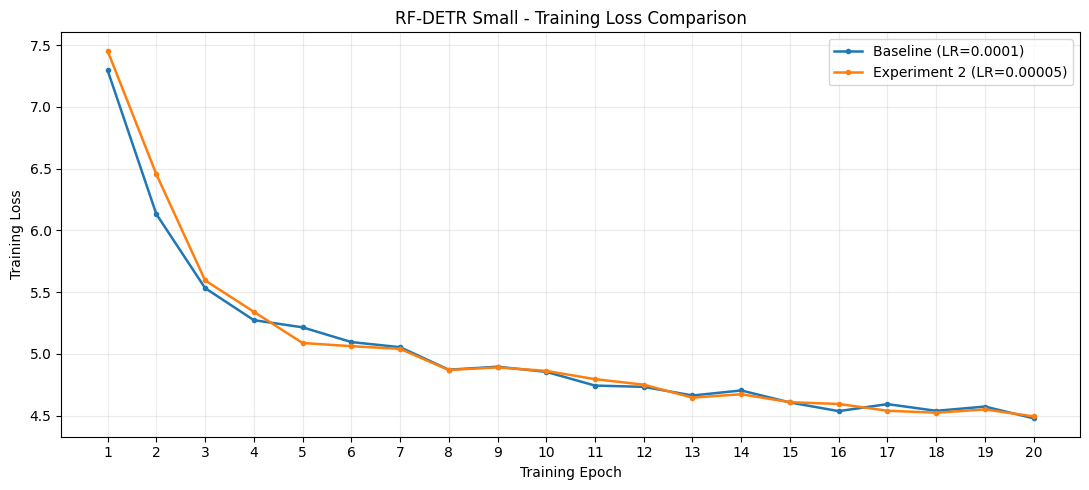

Saved: rfdetr_lr_comparison_loss.png


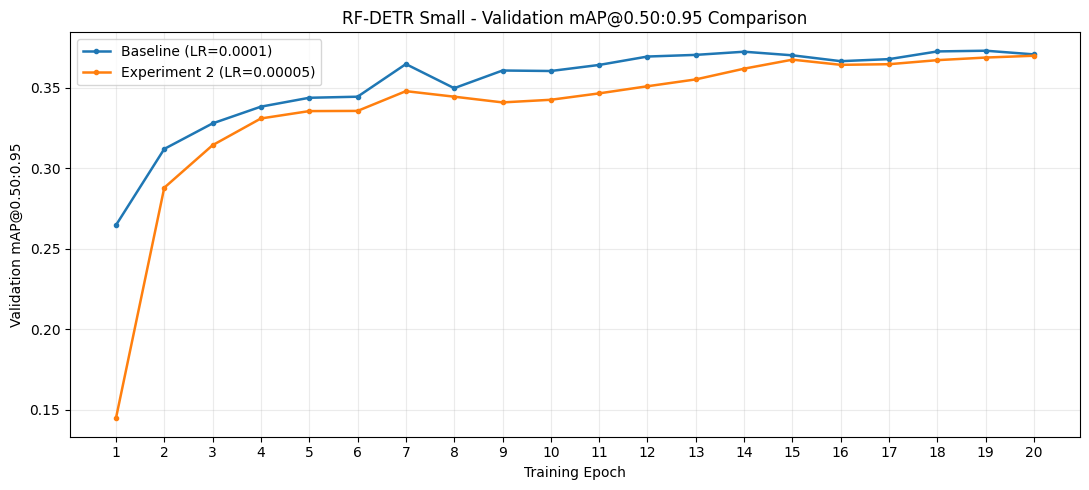

Saved: rfdetr_lr_comparison_map.png


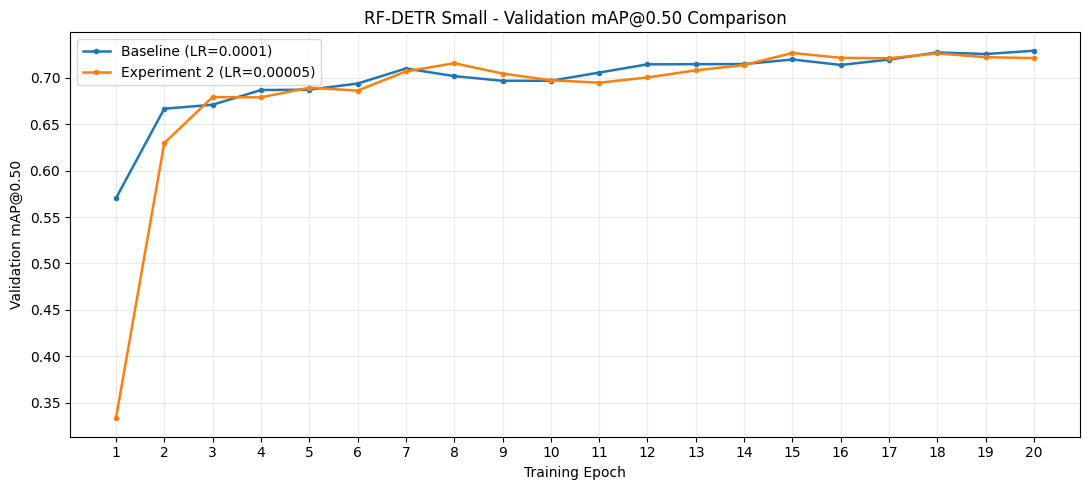

Saved: rfdetr_lr_comparison_map50.png

BEST EXPERIMENT BASED ON VALIDATION EMA mAP50:95
Experiment: Baseline (LR=0.0001)
Best EMA mAP50:95: 0.3729

Hyperparameter Comparison: COMPLETE
Comparison Table: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/evaluation_results/rfdetr_hyperparameter_comparison.csv


In [35]:

# Import libraries for reading experiment logs and creating figures.
# These allow us to compare both training experiments consistently.
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Define the directories for both completed experiments.
# Each directory contains its own training metrics and checkpoints.
BASELINE_DIR = PROJECT_DIR / "training_outputs" / "rfdetr_small_baseline"
OPTIMIZED_DIR = PROJECT_DIR / "training_outputs" / "rfdetr_small_lr_00005"

# Define the output folders for comparative tables and figures.
# These preserve the original experiment records without modification.
RESULTS_DIR = PROJECT_DIR / "evaluation_results"
VISUALIZATION_DIR = PROJECT_DIR / "visualizations"

# Identify the metrics files for the baseline and optimized runs.
# Both files are required for the comparison.
experiment_paths = {
    "Baseline (LR=0.0001)": BASELINE_DIR / "metrics.csv",
    "Experiment 2 (LR=0.00005)": OPTIMIZED_DIR / "metrics.csv"
}

# Confirm that the recorded metrics exist for both experiments.
# Stop if an experiment's logging file is missing.
for name, path in experiment_paths.items():
    if not path.is_file():
        raise FileNotFoundError(f"{name}: {path}")

# Define the recorded metrics used for comparison.
# Validation mAP@0.50:0.95 is our primary model selection metric.
metric_columns = [
    "train/loss",
    "val/ema_mAP_50_95",
    "val/ema_mAP_50",
    "val/mAP_50_95",
    "val/mAP_50",
    "val/mAP_75",
    "val/precision",
    "val/recall",
    "val/F1"
]

# Create a dictionary for cleaned epoch-level metrics.
# Each training run will be processed independently.
experiment_data = {}

# Read and organize the training metrics from each experiment.
# This accounts for sparse rows produced by PyTorch Lightning.
for experiment_name, metrics_path in experiment_paths.items():

    # Load the original CSV file without modifying it.
    # The logs contain separate training and validation records.
    raw_df = pd.read_csv(metrics_path)

    # Verify that the epoch identifier is present.
    # We need it to align both experiments correctly.
    if "epoch" not in raw_df.columns:
        raise ValueError(f"Missing epoch column: {metrics_path}")

    # Convert epoch identifiers to numeric values.
    # Human-readable epoch numbers begin at one.
    raw_df["epoch"] = pd.to_numeric(raw_df["epoch"], errors="coerce")
    raw_df = raw_df.dropna(subset=["epoch"]).copy()
    raw_df["Epoch"] = raw_df["epoch"].astype(int) + 1

    # Select metrics that were recorded in the current experiment.
    # Missing optional metric columns are safely excluded.
    available = [c for c in metric_columns if c in raw_df.columns]

    # Convert values into numeric form before aggregation.
    # Non-numeric records become missing values.
    for column in available:
        raw_df[column] = pd.to_numeric(raw_df[column], errors="coerce")

    # Define the appropriate aggregation method per metric.
    # Training loss is averaged; validation metrics use the final recorded value.
    aggregation = {
        column: "mean" if column == "train/loss" else "last"
        for column in available
    }

    # Aggregate the metrics into one row per epoch.
    # This avoids counting separate logging events as additional epochs.
    epoch_df = (
        raw_df.groupby("Epoch", as_index=False)
        .agg(aggregation)
        .sort_values("Epoch")
    )

    # Store the cleaned epoch-level results.
    # Both runs will be compared using these tables.
    experiment_data[experiment_name] = epoch_df

# Define a helper to retrieve the last or highest recorded value.
# Missing metrics return NaN rather than an invented numerical result.
def get_metric(df, column, use_best=False):

    if column not in df.columns:
        return np.nan

    values = df[column].dropna()

    if values.empty:
        return np.nan

    return float(values.max() if use_best else values.iloc[-1])

# Create a table of the experiments' final and best metrics.
# The best EMA mAP will guide checkpoint selection.
comparison_records = []

for name, df in experiment_data.items():

    comparison_records.append({
        "Experiment": name,
        "Epochs": len(df),
        "Final Train Loss": get_metric(df, "train/loss"),
        "Best EMA mAP50:95": get_metric(
            df, "val/ema_mAP_50_95", use_best=True
        ),
        "Final mAP50": get_metric(df, "val/mAP_50"),
        "Final mAP50:95": get_metric(df, "val/mAP_50_95"),
        "Final mAP75": get_metric(df, "val/mAP_75"),
        "Final Precision": get_metric(df, "val/precision"),
        "Final Recall": get_metric(df, "val/recall"),
        "Final F1": get_metric(df, "val/F1")
    })

# Convert the results into a structured comparison table.
# The table will be exported for the final project report.
comparison_df = pd.DataFrame(comparison_records)

# Save the numerical experiment comparison.
# This ensures all calculated metrics remain available in Google Drive.
comparison_path = RESULTS_DIR / "rfdetr_hyperparameter_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

# Display the experiment comparison results.
# These values summarize the effects of reducing the learning rate.
print("=" * 80)
print("CO2.2 - RF-DETR LEARNING RATE EXPERIMENT COMPARISON")
print("=" * 80)

print(comparison_df.round(4).to_string(index=False))

# Define a function to compare one metric across both experiments.
# Each graph uses the same epochs and metric definition.
def plot_experiment_comparison(column, title, ylabel, filename):

    # Create a separate figure for the selected metric.
    # This helps keep report figures clear and readable.
    plt.figure(figsize=(11, 5))

    plotted = False

    # Plot both experimental runs using their recorded epoch values.
    # Missing records are excluded rather than replaced with zero.
    for name, df in experiment_data.items():

        if column not in df.columns:
            continue

        valid = df[["Epoch", column]].dropna()

        if valid.empty:
            continue

        plt.plot(
            valid["Epoch"],
            valid[column],
            marker="o",
            markersize=3,
            linewidth=1.8,
            label=name
        )

        plotted = True

    # Avoid saving an empty figure when no metric was recorded.
    # This ensures that every graph contains real experimental data.
    if not plotted:
        plt.close()
        print("Metric unavailable:", column)
        return

    # Add descriptive labels and a legend.
    # These identify the metric and learning rate configurations.
    plt.title(title)
    plt.xlabel("Training Epoch")
    plt.ylabel(ylabel)
    plt.xticks(range(1, 21))
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    # Save the graph as a high-resolution image.
    # The file can later be inserted into the PDF report.
    save_path = VISUALIZATION_DIR / filename
    plt.savefig(save_path, dpi=200, bbox_inches="tight")

    # Display the graph in Google Colab.
    # The comparison shows the recorded training or validation trends.
    plt.show()
    print("Saved:", save_path.name)

# Compare training loss across the two experiments.
# This shows how optimization progressed under each learning rate.
plot_experiment_comparison(
    "train/loss",
    "RF-DETR Small - Training Loss Comparison",
    "Training Loss",
    "rfdetr_lr_comparison_loss.png"
)

# Compare standard validation mAP@0.50:0.95.
# This is the main performance metric for the learning rate experiment.
plot_experiment_comparison(
    "val/mAP_50_95",
    "RF-DETR Small - Validation mAP@0.50:0.95 Comparison",
    "Validation mAP@0.50:0.95",
    "rfdetr_lr_comparison_map.png"
)

# Compare validation mAP@0.50 for both experiments.
# This reveals whether the learning rate affected easier-IoU detection.
plot_experiment_comparison(
    "val/mAP_50",
    "RF-DETR Small - Validation mAP@0.50 Comparison",
    "Validation mAP@0.50",
    "rfdetr_lr_comparison_map50.png"
)

# Identify the experiment with the highest recorded EMA validation mAP.
# Model selection must be based on validation data, not the test set.
valid_candidates = comparison_df.dropna(
    subset=["Best EMA mAP50:95"]
)

if valid_candidates.empty:
    print("\nNo valid EMA mAP values found for model selection.")
else:
    best_run = valid_candidates.loc[
        valid_candidates["Best EMA mAP50:95"].idxmax()
    ]

    print("\nBEST EXPERIMENT BASED ON VALIDATION EMA mAP50:95")
    print("Experiment:", best_run["Experiment"])
    print("Best EMA mAP50:95:", round(best_run["Best EMA mAP50:95"], 4))

# Confirm completion of the comparison procedure.
# All result files are now available for final project documentation.
print("\nHyperparameter Comparison: COMPLETE")
print("Comparison Table:", comparison_path)


## 8.1 GitHub Repository Organization and Documentation

This section prepares the software artifacts and documentation required for publishing the RF-DETR Small pedestrian detection project in a GitHub repository. The repository will contain the Google Colab implementation, software dependency information, experimental configuration files, and a README document describing the project's objectives, dataset preparation, training procedure, and evaluation methodology.

The preparation process creates an organized repository directory and copies selected non-sensitive experimental summaries and visualization outputs. Large training checkpoints, original video recordings, and complete image datasets are excluded from the Git repository to avoid unnecessary storage requirements. Instead, the repository documentation explains how to obtain the dataset and reproduce the experiment using Google Colab.

The repository will support reproducibility and provide access to the Python implementation used for dataset processing, RF-DETR model fine-tuning, quantitative evaluation, and hyperparameter experimentation. The final project notebook will be included when the repository is published, ensuring that the submitted code corresponds to the experiments documented in the final report.

In [36]:

# Import utilities for preparing project documentation and repository files.
# These libraries support file copying, package inspection, and text generation.
from pathlib import Path
from importlib.metadata import version
import shutil
import json

# Define the main directory used for the final GitHub repository package.
# This location is separate from the original experimental files.
REPO_DIR = PROJECT_DIR / "github_repository"

# Create directories for reproducibility and report materials.
# These folders store small files suitable for GitHub.
for folder in ["configs", "results", "figures"]:
    (REPO_DIR / folder).mkdir(parents=True, exist_ok=True)

# Identify the configuration files from both training experiments.
# These preserve the exact hyperparameters used during fine-tuning.
configuration_files = {
    "baseline_training_config.json":
        PROJECT_DIR / "training_outputs" /
        "rfdetr_small_baseline" / "training_config.json",
    "optimization_config.json":
        PROJECT_DIR / "training_outputs" /
        "rfdetr_small_lr_00005" / "optimization_config.json"
}

# Copy both configuration files into the repository.
# Missing files are reported instead of silently ignored.
for filename, source in configuration_files.items():
    if not source.is_file():
        raise FileNotFoundError(source)

    shutil.copy2(source, REPO_DIR / "configs" / filename)

# Define the evaluation tables needed to reproduce the reported findings.
# These contain aggregated results rather than the original image dataset.
result_names = [
    "final_dataset_table.csv",
    "final_detection_outcomes.csv",
    "final_performance_table.csv",
    "rfdetr_hyperparameter_comparison.csv",
    "rfdetr_epoch_metrics.csv"
]

# Copy available result tables into the repository.
# The experimental files in Google Drive remain unchanged.
for filename in result_names:
    source = PROJECT_DIR / "evaluation_results" / filename

    if not source.is_file():
        raise FileNotFoundError(source)

    shutil.copy2(source, REPO_DIR / "results" / filename)

# Define the figures documenting training and evaluation.
# These provide visual evidence for the final project report.
figure_names = [
    "rfdetr_training_loss.png",
    "rfdetr_validation_map.png",
    "rfdetr_precision_recall_f1.png",
    "rfdetr_detection_error_analysis.png",
    "rfdetr_lr_comparison_loss.png",
    "rfdetr_lr_comparison_map.png",
    "rfdetr_lr_comparison_map50.png"
]

# Copy the generated figures into the repository package.
# These files allow readers to inspect the experimental results.
for filename in figure_names:
    source = PROJECT_DIR / "visualizations" / filename

    if not source.is_file():
        raise FileNotFoundError(source)

    shutil.copy2(source, REPO_DIR / "figures" / filename)

# Record the installed packages used in the project.
# Version pinning helps readers recreate a similar software environment.
dependency_names = [
    "rfdetr",
    "torch",
    "torchvision",
    "pycocotools",
    "supervision",
    "matplotlib",
    "pandas",
    "opencv-python-headless",
    "Pillow",
    "PyYAML",
    "numpy",
    "albumentations"
]

# Create the dependency list using available installed versions.
# RF-DETR training extras are included for trainer compatibility.
requirements_lines = ['rfdetr[train]==' + version("rfdetr")]

for package in dependency_names[1:]:
    try:
        requirements_lines.append(f"{package}=={version(package)}")
    except Exception:
        print("Package version not available:", package)

# Save the dependencies for future setup and reproduction.
# Colab's CUDA-compatible PyTorch installation may require separate setup.
(REPO_DIR / "requirements.txt").write_text(
    "\n".join(requirements_lines) + "\n",
    encoding="utf-8"
)

# Create Git exclusion rules for datasets and large model checkpoints.
# These prevent accidental publication of unnecessary training files.
gitignore_text = """
__pycache__/
.ipynb_checkpoints/
.venv/
*.pth
*.ckpt
*.pt
*.zip
dataset_original/
dataset_processed/
training_outputs/
*.log
"""

(REPO_DIR / ".gitignore").write_text(
    gitignore_text.strip() + "\n",
    encoding="utf-8"
)

# Prepare the project README using the completed experiment details.
# Its instructions describe the notebook and original dataset requirements.
readme_text = """# RF-DETR Small Pedestrian Detection

## Project Overview

This project fine-tunes RF-DETR Small for single-class pedestrian object detection using a chronologically partitioned video-frame dataset.

## Dataset

- Source: Previously annotated pedestrian video frames
- Total original images: 1,279
- Training images: 867
- Validation images: 185
- Testing images: 187
- Excluded temporal buffer images: 40
- Object class: person
- Annotation format: YOLO bounding boxes

All frames originate from one continuous video. Consequently, the evaluation assesses performance on later frames from the same scene, rather than an independent camera environment.

The dataset archive is not included in this repository. Obtain the original annotated dataset separately and follow the notebook's dataset preparation procedure.

## Model

- Architecture: RF-DETR Small
- Framework: PyTorch and RF-DETR
- Initial weights: Official pretrained RF-DETR Small checkpoint
- Input resolution: 512 x 512
- Fine-tuning epochs: 20
- Physical batch size: 4
- Gradient accumulation steps: 4
- Baseline learning rate: 0.0001
- Optimization experiment learning rate: 0.00005

## Google Colab Setup

1. Open the accompanying `.ipynb` notebook in Google Colab.
2. Enable an NVIDIA GPU runtime.
3. Install the required dependencies using the notebook setup cells.
4. Mount Google Drive and prepare the annotated pedestrian dataset.
5. Run the dataset verification and chronological splitting cells.
6. Run RF-DETR training using the baseline hyperparameters.
7. Run validation analysis and evaluate the trained checkpoint.
8. Optionally reproduce the second learning-rate experiment.

The notebook uses a Google Drive project directory. Adjust its paths to match your own Drive before running the code.

For compatible PyTorch and CUDA installation instructions, consult the official PyTorch documentation.

## Evaluation

The selected baseline model was evaluated on 187 chronologically reserved test images with 535 ground-truth pedestrian annotations.

At confidence threshold 0.30 and matching IoU threshold 0.50:

- True positives: 328
- False positives: 160
- False negatives: 207
- Precision: 67.21%
- Recall: 61.31%
- F1 score: 64.13%
- Mean matched IoU: 75.46%

COCO evaluation:

- mAP@0.50: 65.87%
- mAP@0.75: 28.19%
- mAP@0.50:0.95: 32.77%

Matched-object classification accuracy was 100% among 328 matched detections. This is a single-class task and is not overall detection accuracy.

## Learning Rate Comparison

The baseline achieved a best validation EMA mAP@0.50:0.95 of 37.29%, compared with 36.98% for the learning rate 0.00005 experiment.

The baseline was retained using the validation metric as the selection criterion.

## Repository Contents

- Notebook: Complete data preparation, training, and evaluation workflow
- `configs/`: Hyperparameter configurations
- `results/`: Evaluation and comparison tables
- `figures/`: Generated experimental visualizations
- `requirements.txt`: Recorded dependency versions

## Limitations

The dataset originates from a single camera recording, and the training and testing images share scene characteristics. Small and distant pedestrians were more difficult to detect. Independent-camera validation and additional datasets are recommended for future work.
"""

# Write the project README to the repository directory.
# This provides context and instructions for reviewers.
(REPO_DIR / "README.md").write_text(
    readme_text,
    encoding="utf-8"
)

# Check whether the final notebook has been added to the package.
# Colab notebooks must be downloaded or copied into this folder separately.
notebook_files = list(REPO_DIR.glob("*.ipynb"))

# Display the repository files and directory structure.
# This helps verify the artifacts prepared for submission.
print("=" * 75)
print("CO2.2 - GITHUB REPOSITORY PREPARATION")
print("=" * 75)

for path in sorted(REPO_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(REPO_DIR))

# Report whether the primary notebook still needs to be added.
# The repository is incomplete until the notebook is included.
print("\nNotebook Included:", bool(notebook_files))
print("Repository Directory:", REPO_DIR)
print("\nGitHub Repository Preparation: COMPLETE")


CO2.2 - GITHUB REPOSITORY PREPARATION
.gitignore
README.md
configs/baseline_training_config.json
configs/optimization_config.json
figures/rfdetr_detection_error_analysis.png
figures/rfdetr_lr_comparison_loss.png
figures/rfdetr_lr_comparison_map.png
figures/rfdetr_lr_comparison_map50.png
figures/rfdetr_precision_recall_f1.png
figures/rfdetr_training_loss.png
figures/rfdetr_validation_map.png
requirements.txt
results/final_dataset_table.csv
results/final_detection_outcomes.csv
results/final_performance_table.csv
results/rfdetr_epoch_metrics.csv
results/rfdetr_hyperparameter_comparison.csv

Notebook Included: False
Repository Directory: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/github_repository

GitHub Repository Preparation: COMPLETE


## 8.2 Notebook Integration and Repository Verification

This section verifies the inclusion and structural integrity of the completed Google Colab notebook in the RF-DETR pedestrian detection project's GitHub repository package. The notebook serves as the primary implementation artifact, documenting the dataset preparation, RF-DETR model configuration, training, performance evaluation, and learning rate optimization procedures.

The verification procedure checks whether the notebook is present in the repository directory and examines its JSON structure to confirm that it contains executable Python cells and explanatory Markdown cells. It also verifies the presence of the README document, software dependency specifications, experimental configurations, evaluation results, and visualization figures.

This process ensures that the repository package contains the essential implementation and documentation files before publication to GitHub. Dataset archives and large model checkpoints will remain stored separately to maintain a manageable repository size.

In [37]:

# Import libraries for notebook and repository inspection.
# These allow us to verify notebook structure and required files.
from pathlib import Path
import json

# Define the GitHub repository directory.
# This folder was created during Cell 29.
REPO_DIR = (
    PROJECT_DIR / "github_repository"
)

# Define the expected notebook filename.
# The notebook should be uploaded directly into the repository folder.
NOTEBOOK_PATH = (
    REPO_DIR / "CO2.2_RF_DETR_Pedestrian_Detection.ipynb"
)

# Display the repository verification heading.
# This summarizes the required files before publication.
print("=" * 75)
print("CO2.2 - GITHUB REPOSITORY VERIFICATION")
print("=" * 75)

# Verify that the Google Colab notebook exists.
# The notebook contains the project's executable Python implementation.
if NOTEBOOK_PATH.is_file():

    # Read the notebook's JSON structure.
    # Jupyter notebooks contain metadata, code cells, and Markdown cells.
    with open(NOTEBOOK_PATH, "r", encoding="utf-8") as file:
        notebook_data = json.load(file)

    # Confirm that the file follows the notebook format.
    # Notebook format version 4 is expected.
    notebook_version = notebook_data.get("nbformat")

    # Count the executable Python code cells.
    # Markdown cells are excluded from this count.
    code_cells = sum(
        cell.get("cell_type") == "code"
        for cell in notebook_data.get("cells", [])
    )

    # Count the explanatory Markdown text cells.
    # These provide academic descriptions of the implementation.
    markdown_cells = sum(
        cell.get("cell_type") == "markdown"
        for cell in notebook_data.get("cells", [])
    )

    # Display the notebook verification results.
    # These confirm the contents of the uploaded notebook.
    print("\nNOTEBOOK VERIFICATION")
    print("Notebook Found: YES")
    print("Notebook Format Version:", notebook_version)
    print("Python Code Cells:", code_cells)
    print("Markdown Text Cells:", markdown_cells)
    print(
        "Notebook Size (MB):",
        round(NOTEBOOK_PATH.stat().st_size / (1024 ** 2), 2)
    )

else:

    # Report that the notebook still needs to be uploaded.
    # The repository is incomplete until the implementation is included.
    print("\nNotebook Found: NO")
    print("Expected Location:", NOTEBOOK_PATH)

# Define the required repository files.
# These support reproduction and experimental documentation.
required_files = [
    "README.md",
    "requirements.txt",
    ".gitignore",
    "configs/baseline_training_config.json",
    "configs/optimization_config.json",
    "results/final_performance_table.csv",
    "results/rfdetr_hyperparameter_comparison.csv",
    "figures/rfdetr_detection_error_analysis.png"
]

# Check each required file.
# Missing files will be identified before GitHub publication.
missing_files = []

print("\nREPOSITORY FILE VERIFICATION")

for filename in required_files:

    file_path = REPO_DIR / filename
    exists = file_path.is_file()

    print(
        f"{'FOUND' if exists else 'MISSING'}: {filename}"
    )

    if not exists:
        missing_files.append(filename)

# Display the final repository preparation status.
# A successful result means the expected files are present.
print("\n" + "=" * 75)

if NOTEBOOK_PATH.is_file() and not missing_files:
    print("Repository File Verification: PASSED")
else:
    print("Repository File Verification: NEEDS REVIEW")

# Confirm that the inspection has completed.
# GitHub publication will be performed in the next step.
print("Repository Inspection: COMPLETE")


CO2.2 - GITHUB REPOSITORY VERIFICATION

Notebook Found: NO
Expected Location: /content/drive/MyDrive/CO2.2_RF_DETR_Final_Project/github_repository/CO2.2_RF_DETR_Pedestrian_Detection.ipynb

REPOSITORY FILE VERIFICATION
FOUND: README.md
FOUND: requirements.txt
FOUND: .gitignore
FOUND: configs/baseline_training_config.json
FOUND: configs/optimization_config.json
FOUND: results/final_performance_table.csv
FOUND: results/rfdetr_hyperparameter_comparison.csv
FOUND: figures/rfdetr_detection_error_analysis.png

Repository File Verification: NEEDS REVIEW
Repository Inspection: COMPLETE
